# 03 — Hybrid initial conditions: climatology plus observed anomaly (`hybrid_ic`)

No archive year reproduces the observed land and sea-ice anomalies closely (`02_obs_match_ic.ipynb`). This
workflow starts from the restart of the year closest to the model climatology (the `clim` year, as in
`01_clim_match_ic.ipynb`) and adds the observed anomaly on the target date to its key fields, so the state is the
model climatology plus the observed anomaly while staying a spun-up, internally consistent restart. It writes
the adjusted restarts and evaluates them against the observations and the JRA55-FOSIRL 2015 restarts.

| Notebook | Workflow | Method (`OUT_ROOT/YYYYMMDD/<comp>/<method>/`) |
| --- | --- | --- |
| `01_clim_match_ic.ipynb` | climatology-match | `clim` |
| `02_obs_match_ic.ipynb` | observation-match | `obs` (observations chosen by `OBS_SET`) |
| `03_hybrid_ic.ipynb` | climatology + observed anomaly | `hybrid_ic` |
| `04_compare_ic_methods.ipynb` | comparison of the methods | reads the outputs saved by 01-03 |

Each of 01-03 is self-contained: read the data, choose the box size, select or build the initial
conditions, write the restarts, evaluate them against JRA55-FOSIRL 2015, draw the native-mesh maps, and save the
outputs for 04.

Contents: 1. read the input data; 2. choose the box size; 3. base year; 4. increments; 5. write the restarts;
6. evaluation; 7. native-mesh maps; 8. save the outputs; 9. key findings.

Code: `util/anom_restart.py` (increments, writing, state distances, soil profiles), `util/clim_restart.py`,
`util/ic_eval.py`, `util/ic_store.py`. The BruteForce archive and the observations are only read; the base
restarts are copied to the output directory and modified there.

In [1]:
from pathlib import Path
import importlib
import sys
import warnings

import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("util").resolve()))     # run from this directory
import anom_restart
import box_loo
import clim_restart as cr
import ic_eval as ice
import ic_store

# Reload so edits to util/ take effect without restarting the kernel.
for module in (cr, box_loo, anom_restart, ice, ic_store):
    importlib.reload(module)

ice.ensure_proj_data()
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 80     # inline figures; saved figures use FIG_DPI
quiet = lambda *args: None

## Method

Rather than using a selected historical restart without modification, this approach combines a representative model climatological state with observed anomalies for the target initialization date. The goal is to incorporate observed land and sea-ice conditions while retaining the physical consistency of a spun-up E3SM restart.

## 1. Climatological Baseline

The method first selects the `clim` restart year (section 3), with the same metric as `01_clim_match_ic.ipynb` and the candidate years, climatology years, box, and mode set here.

This restart represents the BruteForce simulation state closest to the candidate-year climatology. It serves as the baseline for all restart variables, including those that cannot be directly constrained by observations. This preserves a physically spun-up, internally consistent model state before the observed-anomaly adjustments are applied.

## 2. Incorporating Observed Anomalies

For each observable key field, the target model state is constructed by adding an observed anomaly to the model climatology:

$$
t_i = \bar{x}_i + a_i,
$$

where

$$
a_i =
\operatorname{clip}\left(
\frac{o_{T,i}-\bar{o}_i}{\sigma_i^o},
-z_{\max},z_{\max}
\right)\sigma_i.
$$

Here:

- \(\bar{x}_i\) and \(\sigma_i\) are the model climatological mean and interannual standard deviation at grid point \(i\), over the climatology years (`CLIM_FIRST_YEAR`-`CLIM_LAST_YEAR`; by default the candidate years).
- \(o_{T,i}\) is the observed value on the target initialization date.
- \(\bar{o}_i\) and \(\sigma_i^o\) are the observed climatological mean and interannual standard deviation over the climatology years.
- \(z_{\max}\) limits the magnitude of standardized anomalies to reduce sensitivity to observational artifacts and extreme outliers.

Observational constraints are obtained from **ERA5-Land for terrestrial variables** and **NOAA/NSIDC Climate Data Record (CDR) for sea-ice concentration**.

By transferring standardized anomalies rather than raw differences, the method accounts for systematic differences in climatology and variability between the model and observations.

Two scaling options are supported:

- **`SCALE = "point"` (default):** Standardizes anomalies locally at each grid cell, allowing the model's local variability to determine the anomaly magnitude.
- **`SCALE = "field"`:** Applies a single field-wide variability ratio, \(S_{\mathrm{model}}/S_{\mathrm{obs}}\), to scale observed anomalies.

The anomaly clipping threshold \(z_{\max}\) also helps prevent unrealistic adjustments caused by observational artifacts, such as ERA5/ERA5-Land snow-depth (`sd`) values reaching the 10 m cap over high mountains and along the Antarctic coast.

## 3. Applying Consistent Restart Adjustments

The target anomalies are applied to the selected climatological restart through either multiplicative scaling (`

## Configuration

Every option of the workflow is set here; the sections below only use these names.

In [2]:
# ---- Archive and output locations ----------------------------------------------------------
SRC_ROOT   = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")   # BruteForce restarts, read-only
SRC_PREFIX = "20251024_s2d_spinup"
IC_SOURCE  = "JRA55-FOSIRL"            # source of the archive land, river, and sea-ice restarts (figure labels)
OUT_ROOT   = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions")
OUT_PREFIX = "20251024_s2d_spinup"     # matches my_refcase2 in the hindcast driver
CACHE_DIR  = OUT_ROOT / "cache"        # model and observed key fields, shared by 01-04
DIAG_ROOT  = Path("/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic")
OBS_DATA   = Path("/global/cfs/cdirs/e3sm/zhan391/data")
ERA5_DIR   = Path("/global/cfs/projectdirs/m3522/cmip6/ERA5/e5.oper.an.sfc")

# Observation sets: per-component root and observed fields (ERA5 names; the data format,
# ERA5 0.25 deg, ERA5-Land 1x1, or NOAA/NSIDC 1x1, is recognized from the root layout).
OBS_SETS = {
    "era5land_nsidc": {       # default: ERA5-Land for land, NOAA/NSIDC sea-ice concentration CDR
        "label": "ERA5-Land/NSIDC",
        "root": {"elm": OBS_DATA / "ERA5_LND", "mpassi": OBS_DATA / "NOAA_NSIDC"},
        "fields": {"elm": ["sd", "swvl1", "swvl2-4", "stl1", "stl2-4"], "mpassi": ["ci"]},
    },
    "era5": {                 # ERA5 for land and sea ice
        "label": "ERA5",
        "root": {"elm": ERA5_DIR, "mpassi": ERA5_DIR},
        "fields": {"elm": ["sd", "swvl1", "swvl2-4", "stl1", "stl2-4"], "mpassi": ["ci"]},
    },
}

METHOD  = "hybrid_ic"           # writes OUT_ROOT/YYYYMMDD/<comp>/hybrid_ic/ and DIAG_ROOT/hybrid_ic/
OBS_SET = "era5land_nsidc"      # observations of the anomaly (a key of OBS_SETS)
EVAL_OBS = OBS_SETS[OBS_SET]
OBS_NAME = EVAL_OBS["label"]    # label in tables and figures

# ---- Dates and components ------------------------------------------------------------------
TEST_DATES     = ["2015-02-01", "2015-05-01", "2015-08-01", "2015-11-01"]   # scored against JRA55-FOSIRL 2015
HINDCAST_DATES = ["2026-02-01", "2026-05-01", "2026-08-01", "2026-11-01"]
TARGET_DATES   = TEST_DATES + HINDCAST_DATES
COMPONENTS     = ["elm", "mosart", "mpassi"]   # the river (mosart) always follows the land year

# ---- Years ---------------------------------------------------------------------------------
SEARCH_FIRST_YEAR   = 1995    # candidate years searched; None: first archive year (1980)
SEARCH_LAST_YEAR    = None    # None: last archive year (2018)
EXCLUDE_YEARS       = []      # never selected
CLIM_FIRST_YEAR     = None    # climatology: mean and interannual spread of every model and observed
CLIM_LAST_YEAR      = None    #   field; None and None use the candidate years
EXCLUDE_TARGET_YEAR = True    # leave the target year out of both (2015 cannot select itself)

# ---- Distance and selection ----------------------------------------------------------------
BOX_CHOICE    = "loo"         # "loo": chosen by the leave-one-out test (section 2); or (dlat, dlon); None: model points
LOO_BOXES     = [None, (10, 20), (15, 30), (20, 40), (30, 60), (45, 90)]   # box sizes tested (None: model points)
LOO_SCORES    = {"points": None, "30x60": (30, 60)}   # primary: closeness at model points; tie-breaker: 30x60 means
LOO_OBS       = OBS_SET   # observations of the test (a key of OBS_SETS)
LOO_RECOMPUTE = False         # True reruns the test (about 12 min, one process per month); else reuse a saved one
BOX_SHIFTS    = 4             # placements of the box edges averaged in the distance (1, 2, or 4)
MODE       = "joint"          # "joint": one year for all components; "per_component": each its own
COMPONENT_WEIGHTS = {"elm": 1.0, "mpassi": 1.0}   # weights a_c in the joint distance

# ---- Anomaly (util/anom_restart.py) --------------------------------------------------------
SETTINGS = anom_restart.AnomalySettings(
    scale="point",            # "point": observed standardized anomaly x model std; "field": one ratio per field
    z_max=3.0,                # |anomaly| <= z_max model std devs at each point
    anom_box=None,            # e.g. (10, 20) to smooth the anomaly over lat-lon boxes
    envelope=True,            # keep each column/cell within the range of the archive years read
    ratio_bounds=(0.25, 4.0),
    soil_temp_layers=3,       # used only when continuous_profile=False
    continuous_profile=True,  # soil increments vary smoothly in depth (no steps between layer groups)
    temp_decay_depth=3.0,     # e-folding depth (m) of the temperature increment below 2.89 m
    fields={"elm": ["snow water equivalent", "surface soil water", "subsurface soil water",
                    "surface soil temperature", "subsurface soil temperature"],
            "mpassi": ["NH ice concentration", "SH ice concentration"]},
)
COMPARE_YEARS = True          # also score the clim (base) and obs years in the evaluation

# ---- Evaluation ----------------------------------------------------------------------------
EVAL_DATES   = TEST_DATES     # dates whose actual restarts the initial conditions are compared with
EXAMPLE_DATE = "2015-02-01"   # date of the single-date maps
MAP_DATES    = EVAL_DATES     # dates of the per-date ELM maps

# ---- Output --------------------------------------------------------------------------------
WRITE_OUTPUT = True           # write the restarts to OUT_ROOT/YYYYMMDD/<comp>/<METHOD>/
OVERWRITE    = True           # replace restarts written before
SAVE_DIAG    = True           # figures to DIAG/figure; tables, states, and settings to DIAG/data
FIG_DPI      = 150
DIAG = DIAG_ROOT / METHOD
ice.IC_SOURCE = IC_SOURCE     # labels every archive state in the figures and tables

## 1. Read the input data

One plan per target date with observations on disk (there is no anomaly to add otherwise): the observation
plan `plans[date]` (writes `OUT_ROOT/YYYYMMDD/<comp>/hybrid_ic/`) and the climatology plan `clim_plans[date]` used to
select the base year, both with the same candidate and climatology years. Model and observed key fields are
cached under `CACHE_DIR`. The table gives, for `EXAMPLE_DATE`, the points read, the area-weighted
climatological mean, and the interannual spread `S` over the climatology years.

In [3]:
def years_table(plans):
    """Candidate and climatology years of each plan."""
    span = lambda years: f"{years[0]}-{years[-1]} ({len(years)})"
    return pd.DataFrame({date: {"candidate years": span(p.candidate_years), "climatology years": span(p.clim_years),
                                "excluded": p.excluded_years, "output": {c: str(p.method_dir(c)) for c in (*p.components, "cpl")}}
                         for date, p in plans.items()}).T

common = dict(src_root=SRC_ROOT, out_root=OUT_ROOT, src_prefix=SRC_PREFIX, out_prefix=OUT_PREFIX,
              components=COMPONENTS, first_year=SEARCH_FIRST_YEAR, last_year=SEARCH_LAST_YEAR,
              clim_first_year=CLIM_FIRST_YEAR, clim_last_year=CLIM_LAST_YEAR,
              exclude_years=EXCLUDE_YEARS, exclude_target_year=EXCLUDE_TARGET_YEAR,
              obs_root=EVAL_OBS["root"], obs_fields=EVAL_OBS["fields"])
plans, clim_plans = {}, {}
for date in TARGET_DATES:
    if not cr.era5_available(date, obs_root=EVAL_OBS["root"], obs_fields=EVAL_OBS["fields"], components=COMPONENTS):
        print(f"skip {date}: {EVAL_OBS['label']} not available yet")
        continue
    plans[date] = cr.make_plan(date, "obs", label=METHOD, **common)
    clim_plans[date] = cr.make_plan(date, "clim", label="clim", **common)
ipd.display(years_table(plans))

inputs = pd.concat([cr.input_summary(plan, CACHE_DIR, log=quiet) for plan in plans.values()], ignore_index=True)
ipd.display(inputs[inputs["target_date"] == EXAMPLE_DATE].drop(columns="target_date").round(3))

skip 2026-11-01: ERA5-Land/NSIDC not available yet


,candidate years,climatology years,excluded,output
2015-02-01,1995-2018 (23),1995-2018 (23),[2015],/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2015-05-01,1995-2018 (23),1995-2018 (23),[2015],/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2015-08-01,1995-2018 (23),1995-2018 (23),[2015],/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2015-11-01,1995-2018 (23),1995-2018 (23),[2015],/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2026-02-01,1995-2018 (24),1995-2018 (24),[2026],/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2026-05-01,1995-2018 (24),1995-2018 (24),[2026],/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2026-08-01,1995-2018 (24),1995-2018 (24),[2026],/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...


,component,field,source,variable,years read,points,clim mean,spread S
0,elm,snow water equivalent,model,restart,1995-2018 (23),238725,130.595,26.128
1,elm,snow water equivalent,observed,sd,1995-2018 (23),86727,1.143,0.047
2,elm,surface soil water,model,restart,1995-2018 (23),238725,32.268,4.027
3,elm,surface soil water,observed,swvl1,1995-2018 (23),86727,0.261,0.041
4,elm,subsurface soil water,model,restart,1995-2018 (23),165408,4992.349,35.042
5,elm,subsurface soil water,observed,swvl2-4,1995-2018 (23),86727,0.755,0.050
6,elm,surface soil temperature,model,restart,1995-2018 (23),238725,280.718,2.458
7,elm,surface soil temperature,observed,stl1,1995-2018 (23),86727,278.935,2.251
8,elm,subsurface soil temperature,model,restart,1995-2018 (23),165408,284.179,0.949
9,elm,subsurface soil temperature,observed,stl2-4,1995-2018 (23),86727,282.451,0.851


## 2. Choose the box size

Distances compare area-weighted means over lat-lon boxes of `BOX = (dlat, dlon)` degrees, averaged over
`BOX_SHIFTS` placements of the box edges (standard, and shifted by half a box in latitude, in longitude, and in
both, so the result does not hinge on where the edges fall). The box is chosen by a leave-one-out test on the
archive alone, so the 2015 test dates stay independent of it:

1. For each calendar month of `TARGET_DATES` and each archive year $y$ (`SEARCH_FIRST_YEAR`-`SEARCH_LAST_YEAR`),
   treat $y$ as the unknown target. The observation-matched selection with box $b$ picks, from the other years,
   the year closest to the observed anomaly of $y$ (`LOO_OBS`).
2. Score the pick against the **JRA55-FOSIRL state of $y$** (the model state the selection should find): joint distance over the observable fields or all
   key fields (including sea-ice thickness and snow on ice, which have no observations).

Skill of a pick: $(D_\mathrm{rms}-D_\mathrm{pick})/(D_\mathrm{rms}-D_\mathrm{best})$, with $D_\mathrm{best}$ the
closest candidate (skill 1) and $D_\mathrm{rms}$ the RMS over the candidates (a random pick, skill about 0).

**Decision rule.** The primary criterion is closeness on the native model grid: boxes whose skill at model
points is within two standard errors (paired by held-out year) of the best are tied. Among them, the one with
the highest large-scale skill (both states averaged over 30x60 boxes) is chosen. Every box is judged at these
same two scales. The test uses the candidate years as its climatology.

The result is saved under `DIAG_ROOT/data/` with a name that records the observations, years, and box shifts,
and reused while those settings are unchanged (`LOO_RECOMPUTE = True` reruns it). Set `BOX_CHOICE` to a
`(dlat, dlon)` pair, or `None` for model points, to override the choice. Code: `util/box_loo.py`.

In [4]:
LOO_MONTHS = sorted({d[5:] for d in TARGET_DATES})
LOO_TAG = f"{LOO_OBS}_{SEARCH_FIRST_YEAR or 'start'}-{SEARCH_LAST_YEAR or 'end'}_shift{BOX_SHIFTS}"
LOO_CSV = DIAG_ROOT / "data" / f"box_size_loo_{LOO_TAG}.csv"
LABELS = [box_loo.box_label(b) for b in LOO_BOXES]

loo = box_loo.add_skill(pd.read_csv(LOO_CSV, dtype={"month": str})) if LOO_CSV.is_file() else None
if (LOO_RECOMPUTE or loo is None or not set(LABELS) <= set(loo["box"])
        or not set(LOO_MONTHS) <= set(loo["month"])):
    loo = box_loo.run_loo(LOO_MONTHS, src_root=SRC_ROOT, out_root=OUT_ROOT, cache_dir=CACHE_DIR,
                          first_year=SEARCH_FIRST_YEAR, last_year=SEARCH_LAST_YEAR, boxes=LOO_BOXES,
                          scores=LOO_SCORES, box_shifts=BOX_SHIFTS,
                          obs_root=OBS_SETS[LOO_OBS]["root"], obs_fields=OBS_SETS[LOO_OBS]["fields"])
    LOO_CSV.parent.mkdir(parents=True, exist_ok=True)
    loo.to_csv(LOO_CSV, index=False)
    print(f"saved {LOO_CSV}")
else:
    print(f"read {LOO_CSV}")
loo = loo[loo["box"].isin(LABELS) & loo["month"].isin(LOO_MONTHS)]
print(f"{len(loo)} rows; test years per month: {dict(loo.groupby('month')['year'].nunique())}")

# Mean skill (0 = random year, 1 = best possible year) by box and month, for each scoring scale and field set.
for key in box_loo.score_keys(loo):
    print(f"scored at {key}")
    ipd.display(box_loo.skill_table(loo, key, LABELS).style.format("{:.3f}").highlight_max(axis=0, color="#cde"))

read /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/data/box_size_loo_era5land_nsidc_1995-end_shift4.csv
576 rows; test years per month: {'02-01': np.int64(24), '05-01': np.int64(24), '08-01': np.int64(24), '11-01': np.int64(24)}
scored at points,observable


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.759,0.842,0.751,0.839,0.798
10x20,0.770,0.812,0.797,0.826,0.801
15x30,0.760,0.750,0.793,0.817,0.780
20x40,0.715,0.750,0.763,0.829,0.764
30x60,0.645,0.730,0.670,0.792,0.709
45x90,0.612,0.721,0.607,0.737,0.669


scored at points,all


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.708,0.714,0.589,0.696,0.677
10x20,0.695,0.737,0.677,0.750,0.715
15x30,0.679,0.670,0.655,0.760,0.691
20x40,0.675,0.663,0.650,0.791,0.695
30x60,0.468,0.603,0.524,0.747,0.586
45x90,0.493,0.652,0.603,0.784,0.633


scored at 30x60,observable


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.749,0.729,0.787,0.834,0.775
10x20,0.763,0.755,0.734,0.836,0.772
15x30,0.787,0.825,0.731,0.837,0.795
20x40,0.717,0.858,0.780,0.847,0.800
30x60,0.743,0.888,0.748,0.821,0.800
45x90,0.703,0.834,0.742,0.813,0.773


scored at 30x60,all


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.675,0.675,0.582,0.676,0.652
10x20,0.678,0.707,0.575,0.743,0.676
15x30,0.732,0.694,0.576,0.758,0.690
20x40,0.643,0.707,0.556,0.785,0.673
30x60,0.574,0.725,0.478,0.747,0.631
45x90,0.592,0.729,0.603,0.786,0.678


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/box_size_loo_skill_era5land_nsidc_1995-end_shift4.png


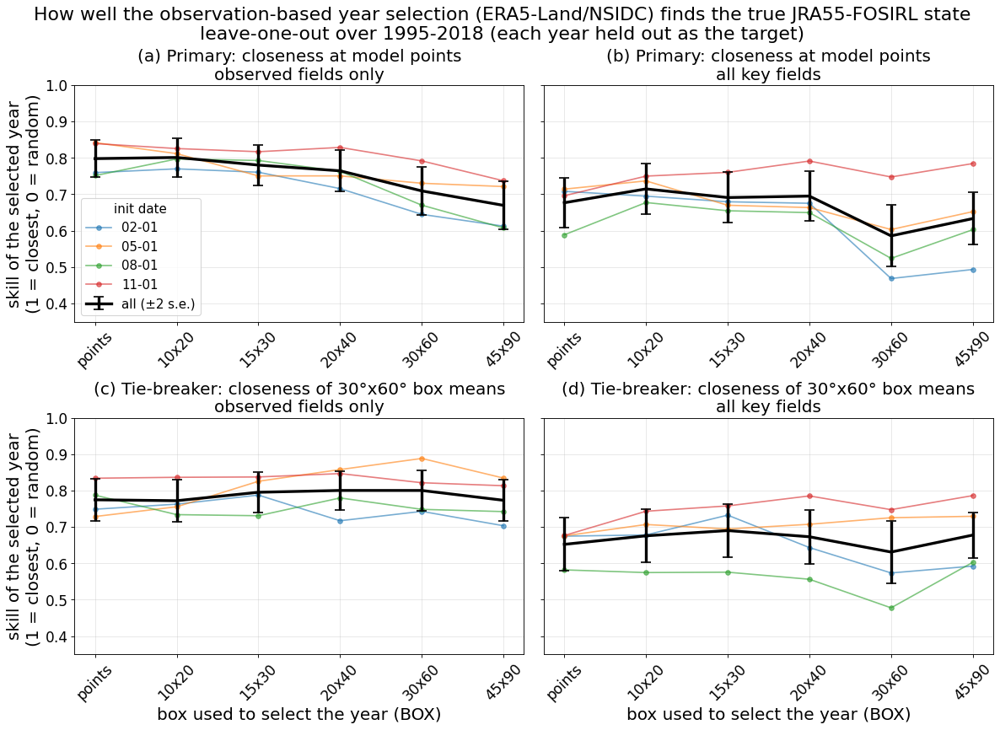

In [5]:
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE    = 18              # base font size; other text scales from it
PANEL_SIZE  = (7.5, 5.5)      # width, height of one panel (inches)
LINE_WIDTH  = 1.5             # per-month lines (the all-month line is 2x)
MARKER_SIZE = 5
YLIM        = (0.35, 1.0)     # None for automatic
LEGEND_LOC  = "lower left"    # legend placed in panel (a)
ROW_TITLES  = {"points": "Primary: closeness at model points",
               "30x60": "Tie-breaker: closeness of 30°x60° box means"}
COL_TITLES  = {"observable": "observed fields only", "all": "all key fields"}
# ---------------------------------------------------------------------------------------------
fs = {"title": FONTSIZE, "label": FONTSIZE, "tick": 0.85 * FONTSIZE,
      "legend": 0.75 * FONTSIZE, "suptitle": 1.1 * FONTSIZE}
rows_, cols_ = list(LOO_SCORES), list(box_loo.FIELD_SETS)
fig, axes = plt.subplots(len(rows_), len(cols_),
                         figsize=(PANEL_SIZE[0] * len(cols_), PANEL_SIZE[1] * len(rows_)),
                         sharey=True, squeeze=False)
x = np.arange(len(LABELS))
for r, scale in enumerate(rows_):
    for c, fset in enumerate(cols_):
        ax, key = axes[r, c], f"{scale},{fset}"
        table = box_loo.skill_table(loo, key, LABELS)
        for month in LOO_MONTHS:
            ax.plot(x, table[month], "o-", lw=LINE_WIDTH, ms=MARKER_SIZE, alpha=0.6, label=month)
        per_year = loo.pivot_table(index=["month", "year"], columns="box", values=f"skill[{key}]")[LABELS]
        se = per_year.std() / np.sqrt(len(per_year))
        ax.errorbar(x, table["all"], yerr=2 * se, color="k", lw=2 * LINE_WIDTH, ms=MARKER_SIZE,
                    capsize=0.3 * FONTSIZE, capthick=LINE_WIDTH, label="all (±2 s.e.)")
        ax.set_xticks(x, LABELS, rotation=45)
        ax.tick_params(labelsize=fs["tick"])
        if YLIM is not None:
            ax.set_ylim(*YLIM)
        ax.set_title(f"({'abcd'[r * len(cols_) + c]}) {ROW_TITLES.get(scale, scale)}\n"
                     f"{COL_TITLES.get(fset, fset)}", fontsize=fs["title"])
        ax.grid(alpha=0.3)
        if r == len(rows_) - 1:
            ax.set_xlabel("box used to select the year (BOX)", fontsize=fs["label"])
        if c == 0:
            ax.set_ylabel("skill of the selected year\n(1 = closest, 0 = random)", fontsize=fs["label"])
axes[0, 0].legend(title="init date", loc=LEGEND_LOC, fontsize=fs["legend"], title_fontsize=fs["legend"])
fig.suptitle(f"How well the observation-based year selection ({OBS_SETS[LOO_OBS]['label']}) finds the true {IC_SOURCE} state\n"
             f"leave-one-out over {loo['year'].min()}-{loo['year'].max()} (each year held out as the target)",
             fontsize=fs["suptitle"])
fig.tight_layout()
ice.save_fig(fig, f"box_size_loo_skill_{LOO_TAG}", DIAG, SAVE_DIAG, dpi=FIG_DPI)
plt.show()

In [6]:
# Primary (native grid): boxes within two standard errors of the best at model points, for both field sets.
# Tie-breaker (large scale): the highest mean skill of the 30x60 box means.
if BOX_CHOICE == "loo":
    chosen, box_choice = box_loo.choose_box(loo, LABELS)
    ipd.display(box_choice.round(3))
    BOX = box_loo.box_from_label(chosen)
else:
    BOX = BOX_CHOICE
print(f"BOX = {BOX}, BOX_SHIFTS = {BOX_SHIFTS}")

,"skill [points,observable]","vs best [points,observable]","skill [points,all]","vs best [points,all]",tied with best on grid,large-scale skill (tie-breaker)
points,0.798,-0.003 ± 0.049,0.677,-0.038 ± 0.058,True,0.713
10x20,0.801,+0.000 ± 0.000,0.715,+0.000 ± 0.000,True,0.724
15x30,0.780,-0.021 ± 0.032,0.691,-0.024 ± 0.045,True,0.743
20x40,0.764,-0.037 ± 0.036,0.695,-0.020 ± 0.052,False,0.737
30x60,0.709,-0.092 ± 0.057,0.586,-0.129 ± 0.079,False,0.716
45x90,0.669,-0.132 ± 0.069,0.633,-0.082 ± 0.083,False,0.725


BOX = (15.0, 30.0), BOX_SHIFTS = 4


## 3. Base year (`clim`) and the `obs` year for comparison

The base is the year closest to the climatology (`01` metric); the year closest to the observed anomaly
(`02` metric, `OBS_SET`) is computed for comparison only.

In [7]:
distances, base_years, obs_years = {}, {}, {}
for date, plan in plans.items():
    distances[date] = cr.compute_distances(clim_plans[date], box=BOX, box_shifts=BOX_SHIFTS,
                                           component_weights=COMPONENT_WEIGHTS, cache_dir=CACHE_DIR, log=quiet)
    base_years[date] = cr.select_years(distances[date], COMPONENTS, MODE)
    obs_years[date] = cr.select_years(
        cr.compute_distances(plan, box=BOX, box_shifts=BOX_SHIFTS, component_weights=COMPONENT_WEIGHTS,
                             cache_dir=CACHE_DIR, log=quiet), COMPONENTS, MODE)

ipd.display(pd.DataFrame({date: {"base (clim) year": base_years[date]["elm"], "base D": distances[date]["joint"].min(),
                                 "obs year": obs_years[date]["elm"]} for date in plans}).T.round(3))

,base (clim) year,base D,obs year
2015-02-01,2010.0,0.838,2014.0
2015-05-01,2004.0,0.843,2014.0
2015-08-01,2009.0,0.798,2017.0
2015-11-01,2008.0,0.866,2014.0
2026-02-01,2010.0,0.839,2010.0
2026-05-01,2009.0,0.840,2011.0
2026-08-01,2009.0,0.786,2016.0


## 4. Increments

`RMS target anomaly` is the anomaly to impose ($t-\bar x$), `RMS base anomaly` the base year's own anomaly that
it replaces, and `RMS realized anomaly` / `corr(realized, target)` what the increment achieves after the bounds
(area-weighted, ELM soil and crop columns averaged to grid cells). `frac changed` / `frac clipped` are area
fractions of the changed points; `frac unreachable` is the fraction where the observations have snow or ice but
the base year has none.

**Map figure.** Each row is one key field; all maps are anomalies from the model climatology. *Reference*
(2015 dates, leftmost): the JRA55-FOSIRL state of the target year, for reference. *Target*: the
observed anomaly on the target date, converted to model units. *Before*: the anomaly of the `clim` year, the
starting state that the adjustment replaces. *After*: the anomaly of the new `hybrid_ic` initial condition. PCC
and RMSE (area-weighted, in the field's units) compare the Reference, Before, and After with the Target. After can fall short
where the physical limits apply (for example, no ice or snow can be added where the starting state has none).

In [8]:
increments, stats = {}, []
for date, plan in plans.items():
    # The JRA55-FOSIRL state of the target year (2015 dates), shown for reference in the map below.
    year = int(date[:4])
    reference_year = year if year not in plan.years and all(
        plan.source(c, year).is_file() for c in ("elm", "mpassi")) else None
    increments[date], table = anom_restart.compute_increments(plan, base_years[date], SETTINGS,
                                                              reference_year=reference_year,
                                                              cache_dir=CACHE_DIR, log=quiet)
    stats.append(table.assign(target_date=date))
stats = pd.concat(stats, ignore_index=True).set_index(["target_date", "component", "field"])
ipd.display(stats.drop(columns=["rule"]).round(3))

base year  anomaly scale S_model/S_obs  RMS target anomaly  RMS base anomaly  RMS realized anomaly  corr(realized, target)  frac changed  frac clipped (envelope)  \
target_date component field                                                                                                                                                                                            
2015-02-01  elm       snow water equivalent             2010                      647.574              19.982            19.675                18.819                   0.966         0.382                    0.017   
                      surface soil water                2010                       99.140               4.424             4.331                 3.831                   0.970         0.993                    0.092   
                      subsurface soil water             2010                      682.834              35.934            33.200                32.698                   0.974         0.996                    0.074   
                      surface soil temperature          2010                        1.107               2.305             2.639                 2.153                   0.988         0.997                    0.078   
                      subsurface soil temperature       2010                        1.156               0.820             1.046                 0.777                   0.988         0.998                    0.044   
            mpassi    NH ice concentration              2010                        1.054               0.037             0.039                 0.040                   0.743         0.087                    0.012   
                      SH ice concentration              2010                        1.110               0.044             0.045                 0.037                   0.623         0.066                    0.001   
2015-05-01  elm       snow water equivalent             2004                      603.309              21.639            24.473                19.552                   0.894         0.168                    0.008   
                      surface soil water                2004                      105.643               4.700             4.710                 4.191                   0.976         0.995                    0.096   
                      subsurface soil water             2004                      705.023              36.887            32.750                33.621                   0.978         0.997                    0.079   
                      surface soil temperature          2004                        1.155               2.786             2.689                 2.617                   0.991         0.995                    0.080   
                      subsurface soil temperature       2004                        0.968               0.810             0.728                 0.761                   0.987         0.997                    0.047   
            mpassi    NH ice concentration              2004                        1.174               0.032             0.041                 0.036                   0.689         0.099                    0.005   
                      SH ice concentration              2004                        1.146               0.061             0.052                 0.050                   0.383         0.053                    0.015   
2015-08-01  elm       snow water equivalent             2009                      441.858               5.079             7.388                 6.202                   0.810         0.009                    0.000   
                      surface soil water                2009                       72.117               3.907             3.069                 3.424                   0.969         0.996                    0.082   
                      subsurface soil water             2009                      753.262              42.122            34.998                39.901              

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/hybrid_ic_increments_20150201.png


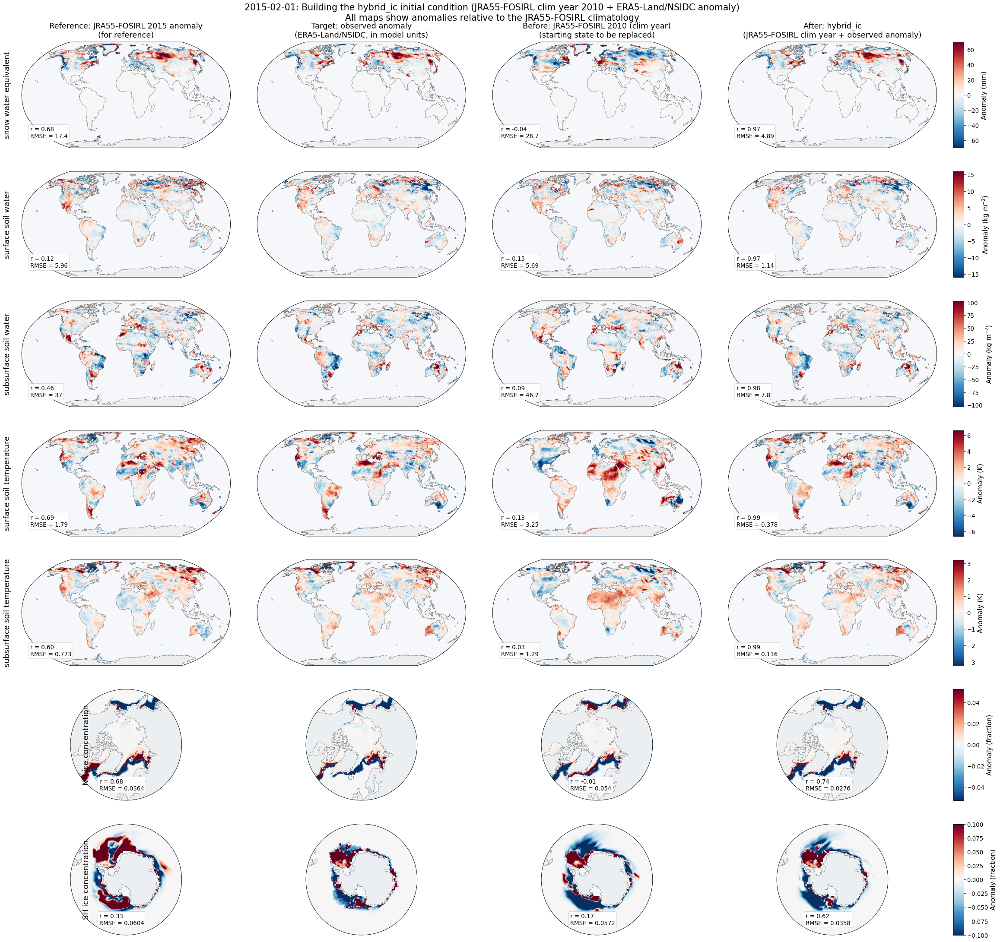

In [9]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.path as mpath

# Anomalies (relative to the model climatology) of the JRA55-FOSIRL state of the
# target year (reference, 2015 dates), the observed target, the starting state
# (before), and the new initial condition (after).
# PCC and RMSE of the reference, before, and after are calculated against the target.
# Land: global maps; sea ice: polar stereographic maps.

# ---- Figure setup (all adjustable settings) -------------------------------
DATE        = EXAMPLE_DATE
FONTSIZE    = 16
PANEL_SIZE  = (6.8, 3.6)
POLAR_LAT   = 50
MARKER      = {"elm": 0.8, "mpassi": 2.5}
PCTL        = 98
CMAP        = "RdBu_r"

LAND_COLOR  = "#eceff1"
OCEAN_COLOR = "#f5f7fa"
COAST_WIDTH = 0.5

UNITS = {
    "snow water equivalent": "mm",
    "surface soil water": "kg m$^{-2}$",
    "subsurface soil water": "kg m$^{-2}$",
    "surface soil temperature": "K",
    "subsurface soil temperature": "K",
    "NH ice concentration": "fraction",
    "SH ice concentration": "fraction",
}

COLUMNS = [
    (
        "target anomaly",
        f"Target: observed anomaly\n({OBS_NAME}, in model units)"
    ),
    (
        "base anomaly",
        f"Before: {IC_SOURCE} {{base}} (clim year)\n(starting state to be replaced)"
    ),
    (
        "realized anomaly",
        f"After: hybrid_ic\n({IC_SOURCE} clim year + observed anomaly)"
    ),
]

REFERENCE_COLUMN = (
    "reference anomaly",
    f"Reference: {IC_SOURCE} {EXAMPLE_DATE[:4]} anomaly\n(for reference)"
)

STATS    = True
# ---------------------------------------------------------------------------

fs = {
    "title": FONTSIZE,
    "row": FONTSIZE,
    "cbar_label": 0.85 * FONTSIZE,
    "tick": 0.75 * FONTSIZE,
    "suptitle": 1.15 * FONTSIZE,
    "stats": 0.75 * FONTSIZE,
}


def vs_target(m, kind):
    """
    Area-weighted pattern correlation coefficient (PCC)
    and RMSE against the target anomaly.
    """
    ok = (
        m["valid"]
        & np.isfinite(m[kind])
        & np.isfinite(m["target anomaly"])
        & np.isfinite(m["weight"])
        & (m["weight"] > 0)
    )

    if not np.any(ok):
        return np.nan, np.nan

    w = m["weight"][ok]
    w = w / w.sum()

    x = m[kind][ok]
    y = m["target anomaly"][ok]

    dx = x - np.sum(w * x)
    dy = y - np.sum(w * y)

    cov = np.sum(w * dx * dy)
    var_x = np.sum(w * dx**2)
    var_y = np.sum(w * dy**2)

    denom = np.sqrt(var_x * var_y)

    pcc = cov / denom if denom > 0 else np.nan
    rmse = np.sqrt(np.sum(w * (x - y)**2))

    return pcc, rmse


PROJ = {
    "NH": ccrs.NorthPolarStereo(),
    "SH": ccrs.SouthPolarStereo(),
    "global": ccrs.Robinson(),
}

theta = np.linspace(0, 2 * np.pi, 100)

CIRCLE = mpath.Path(
    np.vstack([np.sin(theta), np.cos(theta)]).T * 0.5 + 0.5
)

fields = [
    (c, f)
    for c in increments[DATE]
    for f in increments[DATE][c]
]

# The reference column only where the target year's state exists (2015 dates).
c0, f0 = fields[0]
columns = ([REFERENCE_COLUMN] if "reference anomaly" in increments[DATE][c0][f0]["maps"] else []) + COLUMNS
ncol = len(columns)


def region(comp, name):
    return name[:2] if comp == "mpassi" else "global"


# ---- Figure geometry -------------------------------------------------------

title_h = 3.6 * FONTSIZE / 72 + 0.3

heights = [
    PANEL_SIZE[1] * 1.05
    if region(c, f) != "global"
    else PANEL_SIZE[1]
    for c, f in fields
]

total_h = (
    sum(heights)
    + title_h
    + 1.0 * FONTSIZE / 72
    + 0.6
)

left_w = 1.8 * FONTSIZE / 72 + 0.2
cbar_w = 3.2 * FONTSIZE / 72 + 0.5

total_w = left_w + ncol * PANEL_SIZE[0] + cbar_w

fig = plt.figure(figsize=(total_w, total_h))

grid = fig.add_gridspec(
    len(fields),
    ncol + 1,
    height_ratios=heights,
    width_ratios=[1] * ncol + [0.045],
    hspace=0.22,
    wspace=0.035,
    top=1 - (title_h + 1.0 * FONTSIZE / 72) / total_h,
    bottom=0.3 / total_h,
    left=left_w / total_w,
    right=1 - (cbar_w - 0.35) / total_w,
)


# ---- Plot each variable ----------------------------------------------------

for r, (comp, name) in enumerate(fields):

    m = increments[DATE][comp][name]["maps"]

    ok = (
        m["valid"]
        & np.isfinite(m["target anomaly"])
    )

    reg = region(comp, name)

    abs_target = np.abs(m["target anomaly"][ok])

    if abs_target.size and np.isfinite(abs_target).any():
        vmax = np.nanpercentile(abs_target, PCTL)
        if not np.isfinite(vmax) or vmax <= 0:
            vmax = 1.0
    else:
        vmax = 1.0

    for c, (kind, title) in enumerate(columns):

        ax = fig.add_subplot(
            grid[r, c],
            projection=PROJ[reg]
        )

        ax.set_facecolor(OCEAN_COLOR)

        valid = ok & np.isfinite(m[kind])

        if reg == "global":

            ax.set_global()

            ax.add_feature(
                cfeature.LAND,
                facecolor=LAND_COLOR,
                zorder=0
            )

        else:

            lat0, lat1 = (
                (POLAR_LAT, 90)
                if reg == "NH"
                else (-90, -POLAR_LAT)
            )

            ax.set_extent(
                [-180, 180, lat0, lat1],
                crs=ccrs.PlateCarree()
            )

            ax.set_boundary(
                CIRCLE,
                transform=ax.transAxes
            )

            ax.add_feature(
                cfeature.LAND,
                facecolor=LAND_COLOR,
                zorder=1
            )

        sc = ax.scatter(
            m["lon"][valid],
            m["lat"][valid],
            c=m[kind][valid],
            s=MARKER[comp],
            cmap=CMAP,
            vmin=-vmax,
            vmax=vmax,
            transform=ccrs.PlateCarree(),
            rasterized=True,
            zorder=2
        )

        ax.coastlines(
            linewidth=COAST_WIDTH,
            color="0.35",
            zorder=3
        )

        # ---- Column titles ------------------------------------------------

        if r == 0:

            head = title.format(
                base=base_years[DATE][comp]
            )

            ax.set_title(
                head,
                fontsize=fs["title"],
                pad=10
            )

        # ---- PCC / RMSE ---------------------------------------------------

        if STATS and kind != "target anomaly":

            pcc, rmse = vs_target(m, kind)

            badge = (
                f"r = {pcc:.2f}\n"
                f"RMSE = {rmse:.3g}"
            )

            badge_x = 0.26 if reg != "global" else 0.04
            badge_y = 0.08

            ax.text(
                badge_x,
                badge_y,
                badge,
                transform=ax.transAxes,
                fontsize=fs["stats"],
                verticalalignment="bottom",
                horizontalalignment="left",
                bbox=dict(
                    boxstyle="round,pad=0.28",
                    facecolor="white",
                    alpha=0.88,
                    edgecolor="0.75",
                    linewidth=0.6
                ),
                zorder=5
            )

        # ---- Row labels --------------------------------------------------

        if c == 0:

            label_x = 0.18 if reg != "global" else -0.05

            ax.text(
                label_x,
                0.5,
                name,
                transform=ax.transAxes,
                rotation=90,
                ha="right",
                va="center",
                fontsize=fs["row"],
                fontweight="medium"
            )

    # ---- Colorbar for each variable --------------------------------------

    cb = fig.colorbar(
        sc,
        cax=fig.add_subplot(grid[r, ncol])
    )

    cb.set_label(
        f"Anomaly ({UNITS.get(name, '')})",
        fontsize=fs["cbar_label"]
    )

    cb.ax.tick_params(
        labelsize=fs["tick"]
    )


# ---- Main figure title -----------------------------------------------------

fig.suptitle(
    f"{DATE}: Building the hybrid_ic initial condition "
    f"({IC_SOURCE} clim year {base_years[DATE]['elm']} + {OBS_NAME} anomaly)\n"
    f"All maps show anomalies relative to the {IC_SOURCE} climatology",
    fontsize=fs["suptitle"],
    y=1 - 0.2 / total_h,
    va="top"
)


# ---- Save / display --------------------------------------------------------

ice.save_fig(fig, f"hybrid_ic_increments_{DATE.replace('-', '')}", DIAG, SAVE_DIAG, dpi=FIG_DPI)

plt.show()

## 5. Write the restarts

Copies each base restart to `OUT_ROOT/YYYYMMDD/<comp>/hybrid_ic/`, applies the increments there (the source archive is
only read), copies the river restart from the base land year, writes `rpointer.lnd`, `rpointer.rof`,
`rpointer.ice`, and records the plan, base years, settings, and the increment statistics in `anomaly.json`
(one 14.6 GB ELM copy per date). The new files are then re-read to check that their key fields equal the
computed ones. Set `WRITE_OUTPUT = True` to run.

In [10]:
if WRITE_OUTPUT:
    for date, plan in plans.items():
        anom_restart.write_anomaly_restarts(plan, base_years[date], increments[date],
                               stats.loc[date].reset_index(), SETTINGS, overwrite=OVERWRITE)

rows = []
for date, plan in plans.items():
    for comp in COMPONENTS:
        out = plan.output(comp)
        row = {"target_date": date, "component": comp, "base year": base_years[date][comp],
               "written": out.is_file()}
        if out.is_file() and comp in increments[date]:
            written = cr.read_key_fields(comp, out)
            err = 0.0
            for name, inc in increments[date][comp].items():
                values, weight = written[name]
                ok = (weight > 0) & np.isfinite(values) & np.isfinite(inc["new"])
                err = max(err, float(np.max(np.abs(values[ok] - inc["new"][ok])
                                            / (np.abs(inc["new"][ok]).max() or 1.0))))
            row["max rel. key-field error"] = err
        rows.append(row)
ipd.display(pd.DataFrame(rows))

  elm: 20251024_s2d_spinup.elm.r.2010-02-01-00000.nc + anomaly -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150201/hybrid_ic/20251024_s2d_spinup.elm.r.2015-02-01-00000.nc (84 s)


  mosart: 20251024_s2d_spinup.mosart.r.2010-02-01-00000.nc -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150201/hybrid_ic/20251024_s2d_spinup.mosart.r.2015-02-01-00000.nc (0 s)


  mpassi: 20251024_s2d_spinup.mpassi.rst.2010-02-01_00000.nc + anomaly -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150201/hybrid_ic/20251024_s2d_spinup.mpassi.rst.2015-02-01_00000.nc (8 s)


  elm: 20251024_s2d_spinup.elm.r.2004-05-01-00000.nc + anomaly -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150501/hybrid_ic/20251024_s2d_spinup.elm.r.2015-05-01-00000.nc (94 s)


  mosart: 20251024_s2d_spinup.mosart.r.2004-05-01-00000.nc -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150501/hybrid_ic/20251024_s2d_spinup.mosart.r.2015-05-01-00000.nc (0 s)


...

  mpassi: 20251024_s2d_spinup.mpassi.rst.2009-05-01_00000.nc + anomaly -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20260501/hybrid_ic/20251024_s2d_spinup.mpassi.rst.2026-05-01_00000.nc (8 s)


  elm: 20251024_s2d_spinup.elm.r.2009-08-01-00000.nc + anomaly -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20260801/hybrid_ic/20251024_s2d_spinup.elm.r.2026-08-01-00000.nc (113 s)


  mosart: 20251024_s2d_spinup.mosart.r.2009-08-01-00000.nc -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20260801/hybrid_ic/20251024_s2d_spinup.mosart.r.2026-08-01-00000.nc (0 s)


  mpassi: 20251024_s2d_spinup.mpassi.rst.2009-08-01_00000.nc + anomaly -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20260801/hybrid_ic/20251024_s2d_spinup.mpassi.rst.2026-08-01_00000.nc (9 s)


,target_date,component,base year,written,max rel. key-field error
0,2015-02-01,elm,2010,True,4.936085e-08
1,2015-02-01,mosart,2010,True,NaN
2,2015-02-01,mpassi,2010,True,5.081821e-08
3,2015-05-01,elm,2004,True,4.928125e-08
4,2015-05-01,mosart,2004,True,NaN
5,2015-05-01,mpassi,2004,True,5.581033e-08
6,2015-08-01,elm,2009,True,4.882065e-08
7,2015-08-01,mosart,2009,True,NaN
8,2015-08-01,mpassi,2009,True,5.187375e-08
9,2015-11-01,elm,2008,True,4.930495e-08


## 6. Evaluation

The initial-condition state is read back from the written restarts (`WRITE_OUTPUT = True`); otherwise it is
the base year with the computed key fields (`increments`), which leaves out the change of sea-ice thickness and
snow on ice that the concentration ratio implies. With `COMPARE_YEARS`, the base (`clim`) year and the `obs`
year are scored as well.

In [11]:
states, compare = {}, {}
for date, plan in plans.items():
    if WRITE_OUTPUT:
        files = {comp: plan.output(comp) for comp in ("elm", "mpassi") if comp in COMPONENTS}
        states[date] = anom_restart.read_states(plan, {METHOD: files})[METHOD]
    else:
        states[date] = ic_store.year_states(plan, base_years[date], CACHE_DIR)
        for comp, fields in increments[date].items():
            states[date][comp].update({name: inc["new"] for name, inc in fields.items()})
    compare[date] = {"clim year": ic_store.year_states(plan, base_years[date], CACHE_DIR),
                     "obs year": ic_store.year_states(plan, obs_years[date], CACHE_DIR)} if COMPARE_YEARS else {}

### 6.1 Common score: distance of the initial condition from the observations and from JRA55-FOSIRL 2015

The same score in all three workflows (`ic_store.evaluate_states`, saved as `state_distance.csv`): the joint
distance D (observable fields) of the initial-condition state from the observed standardized anomaly on the
target date, and from the JRA55-FOSIRL 2015 IC (2015 dates), on `BOX` boxes and at model points. Lower is closer;
a typical candidate year has D of about 1.4-1.5 from the observations.

In [12]:
state_eval = pd.concat([ic_store.evaluate_states(plans[d], {**compare[d], METHOD: states[d]}, box=BOX,
                                                 cache_dir=CACHE_DIR) for d in plans], ignore_index=True)
ipd.display(state_eval.pivot_table(index=["versus", "scale", "target_date"], columns="state", values="joint").round(3))

state                                 clim year  hybrid_ic  obs year
versus            scale  target_date                                
JRA55-FOSIRL 2015 15x30  2015-02-01       1.381      0.959     1.163
                         2015-05-01       1.465      1.006     0.961
                         2015-08-01       1.168      0.803     1.135
                         2015-11-01       1.547      0.975     1.210
                  points 2015-02-01       1.402      1.143     1.302
                         2015-05-01       1.464      1.194     1.156
                         2015-08-01       1.320      1.090     1.299
                         2015-11-01       1.502      1.111     1.272
observed          15x30  2015-02-01       1.237      0.625     1.108
                         2015-05-01       1.305      0.704     1.086
                         2015-08-01       1.223      0.554     1.179
                         2015-11-01       1.456      0.712     1.163
                         2026-02-01       1.292      0.703     1.292
                         2026-05-01       1.457      0.605     1.252
                         2026-08-01       1.502      0.592     1.328
                  points 2015-02-01       1.250      0.699     1.287
                         2015-05-01       1.355      0.843     1.307
                         2015-08-01       1.302      0.704     1.316
                         2015-11-01       1.456      0.815     1.269
                         2026-02-01       1.361      0.828     1.361
                         2026-05-01       1.477      0.780     1.375
                         2026-08-01       1.482      0.791     1.466

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/hybrid_ic_joint_distance.png


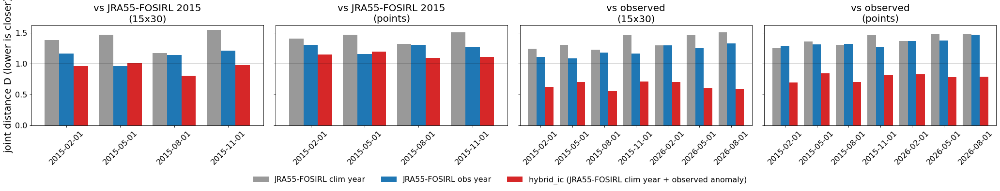

In [13]:
# Joint distance by date: lower is closer to the target.
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE   = 18                  # base font size; other text scales from it
PANEL_SIZE = (6.5, 5.0)          # width, height of one panel (inches)
STATES     = [s for s in ["clim year", "obs year", METHOD] if s in set(state_eval["state"])]   # bars, in order
COLORS     = ["0.6", "tab:blue", "tab:red"][-len(STATES):]
BAR_WIDTH  = 0.8
YLIM       = None                # e.g. (0, 1.8); None for automatic
# ---------------------------------------------------------------------------------------------
fs = {"title": FONTSIZE, "label": FONTSIZE, "tick": 0.8 * FONTSIZE, "legend": 0.8 * FONTSIZE}
groups = state_eval.pivot_table(index=["versus", "scale", "target_date"], columns="state",
                                values="joint").groupby(level=["versus", "scale"])
fig, axes = plt.subplots(1, len(groups), figsize=(PANEL_SIZE[0] * len(groups), PANEL_SIZE[1]),
                         sharey=True, squeeze=False)
for ax, ((versus, scale), table) in zip(axes[0], groups):
    table = table.droplevel(["versus", "scale"])[STATES]
    table.plot.bar(ax=ax, rot=45, width=BAR_WIDTH, color=COLORS, legend=False)
    ax.axhline(1, color="k", lw=0.8)
    ax.set_title(f"vs {versus}\n({scale})", fontsize=fs["title"])
    ax.set_xlabel("")
    ax.tick_params(labelsize=fs["tick"])
    if YLIM is not None:
        ax.set_ylim(*YLIM)
axes[0, 0].set_ylabel("joint distance D (lower is closer)", fontsize=fs["label"])
LEGEND = {"clim year": f"{IC_SOURCE} clim year", "obs year": f"{IC_SOURCE} obs year",
          METHOD: f"hybrid_ic ({IC_SOURCE} clim year + observed anomaly)"}
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, [LEGEND.get(l, l) for l in labels], fontsize=fs["legend"], loc="lower center",
           ncol=len(STATES), frameon=False)
fig.tight_layout(rect=(0, 0.1, 1, 1))
ice.save_fig(fig, "hybrid_ic_joint_distance", DIAG, SAVE_DIAG, dpi=FIG_DPI)
plt.show()

In [14]:
# Field distances averaged over dates.
field_cols = [c for c in state_eval.columns if ": " in c]
ipd.display(state_eval.groupby(["versus", "scale", "state"])[field_cols].mean().T.round(3))

versus                           JRA55-FOSIRL 2015                                                  observed                                                
scale                                        15x30                       points                        15x30                       points                   
state                                    clim year hybrid_ic obs year clim year hybrid_ic obs year clim year hybrid_ic obs year clim year hybrid_ic obs year
elm: snow water equivalent                   1.318     1.001    0.777     1.413     1.205    0.806     1.197     0.779    1.096     1.226     1.033    1.344
elm: surface soil water                      1.415     0.921    1.325     1.471     1.173    1.319     1.378     0.636    1.400     1.428     0.795    1.437
elm: subsurface soil water                   1.330     0.910    1.204     1.418     1.140    1.210     1.525     0.475    1.579     1.476     0.690    1.528
elm: surface soil temperature                1.339     0.527    1.191     1.389     0.788    1.318     1.392     0.340    1.241     1.410     0.382    1.354
elm: subsurface soil temperature             1.360     0.704    1.071     1.336     0.886    1.168     1.592     0.698    1.363     1.477     0.684    1.371
mpassi: NH ice concentration                 1.192     0.837    1.055     1.353     1.155    1.384     1.103     0.446    1.026     1.321     0.714    1.303
mpassi: SH ice concentration                 1.538     1.128    1.095     1.493     1.250    1.250     1.356     0.754    0.983     1.370     0.853    1.217

### 6.2 Field-level similarity to JRA55-FOSIRL 2015

For every key field, the initial condition and the observed anomaly (`EVAL_OBS`) are compared with the
JRA55-FOSIRL 2015 IC: `d_box`/`r_box` (RMS difference / pattern correlation of standardized anomalies on `BOX` boxes),
`d_grid`/`r_grid` (the same at model points), and `RMSE`, `PCC`, `bias` of the state itself.

[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/field_similarity.csv


d_box  r_box  d_grid  r_grid    RMSE    PCC   bias
component field                       source                                                             
elm       snow water equivalent       ERA5-Land/NSIDC  0.912  0.560   1.200   0.175     NaN    NaN    NaN
                                      hybrid_ic        1.001  0.473   1.185   0.284  26.404  0.996  0.472
          subsurface soil temperature ERA5-Land/NSIDC  0.652  0.744   0.868   0.578     NaN    NaN    NaN
                                      hybrid_ic        0.704  0.701   0.880   0.549   0.704  0.999  0.042
          subsurface soil water       ERA5-Land/NSIDC  0.981  0.591   1.180   0.394     NaN    NaN    NaN
                                      hybrid_ic        0.910  0.621   1.138   0.386  40.137  1.000 -1.189
          surface soil temperature    ERA5-Land/NSIDC  0.457  0.863   0.718   0.707     NaN    NaN    NaN
                                      hybrid_ic        0.527  0.815   0.779   0.643   1.911  0.994  0.058
          surface soil water          ERA5-Land/NSIDC  0.814  0.677   1.211   0.377     NaN    NaN    NaN
                                      hybrid_ic        0.921  0.561   1.172   0.327   4.478  0.979 -0.040
mpassi    NH ice concentration        ERA5-Land/NSIDC  0.654  0.767   1.030   0.486     NaN    NaN    NaN
                                      hybrid_ic        0.837  0.566   1.155   0.267   0.062  0.961 -0.001
          NH ice thickness            hybrid_ic        0.770  0.202   1.167   0.106   0.178  0.945  0.004
          NH snow on ice              hybrid_ic        1.050  0.223   1.210   0.181   0.024  0.830  0.000
          SH ice concentration        ERA5-Land/NSIDC  0.602  0.852   0.993   0.563     NaN    NaN    NaN
                                      hybrid_ic        1.128  0.391   1.250   0.177   0.073  0.909 -0.005
          SH ice thickness            hybrid_ic        1.246  0.294   1.418   0.065   0.166  0.857 -0.008
          SH snow on ice              hybrid_ic        1.866 -0.157   1.732  -0.047   0.042  0.756 -0.003

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/2015_field_similarity_bars.png


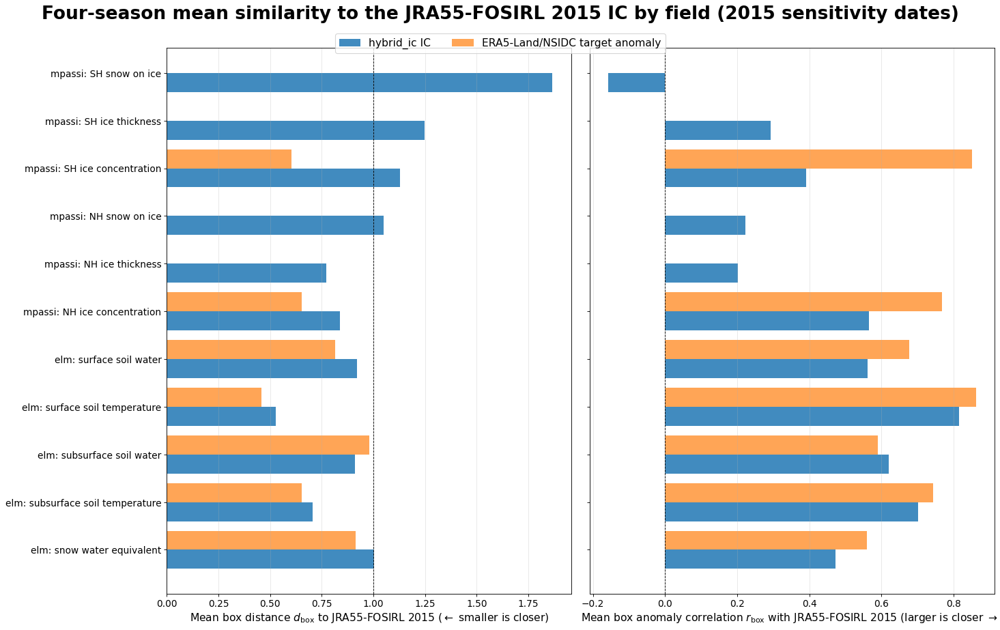

In [15]:
eval_plans = {(METHOD, d): plans[d] for d in EVAL_DATES if d in plans}

# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE = 14
PANEL_SIZE = None
# ---------------------------------------------------------------------------------------------
similarity = pd.concat([
    ice.field_similarity_table(plans[d], int(d[:4]), {METHOD: base_years[d]["elm"]}, obs_plans={EVAL_OBS["label"]: plans[d]},
                               states={METHOD: states[d]}, box=BOX, cache_dir=CACHE_DIR)
    for d in EVAL_DATES if d in plans
], ignore_index=True)
ice.save_table(similarity, "field_similarity", DIAG, SAVE_DIAG)
mean_by_source = (similarity.groupby(["component", "field", "source"])
                  [["d_box", "r_box", "d_grid", "r_grid", "RMSE", "PCC", "bias"]].mean())
ipd.display(mean_by_source.round(3))

fig = ice.plot_field_similarity_bars(similarity, fontsize=FONTSIZE, panel_size=PANEL_SIZE)
ice.save_fig(fig, "2015_field_similarity_bars", DIAG, SAVE_DIAG, dpi=FIG_DPI)
plt.show()

### 6.3 Global and hemispheric totals against JRA55-FOSIRL 2015

In [16]:
global_summary = ice.global_summary_table(EVAL_DATES, {(METHOD, d): base_years[d] for d in EVAL_DATES if d in plans},
                                          SRC_ROOT, src_prefix=SRC_PREFIX, components=COMPONENTS,
                                          files={(METHOD, d): {c: plans[d].output(c) for c in COMPONENTS}
                                                 for d in EVAL_DATES if d in plans})
global_summary = global_summary.rename(columns={f"{METHOD} year": "year", METHOD: "value",
                                                f"{METHOD} - actual": "value - actual"})
ice.save_table(global_summary, "global_summary", DIAG, SAVE_DIAG)
ipd.display(global_summary.round(3))

[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/global_summary.csv


,target_date,component,quantity,actual_2015,year,value,value - actual
0,2015-02-01,elm,mean H2OSNO (mm),348.912,2010,349.726,0.814
1,2015-02-01,elm,snow-covered column fraction,0.626,2010,0.643,0.017
2,2015-02-01,elm,top-3-layer soil liquid (kg m-2),10.719,2010,10.254,-0.465
3,2015-02-01,elm,top-3-layer soil ice (kg m-2),35.257,2010,35.512,0.255
4,2015-02-01,elm,top soil layer T (K),270.704,2010,270.760,0.056
...,...,...,...,...,...,...,...
63,2015-11-01,mpassi,NH snow volume (1e3 km3),0.591,2008,0.620,0.029
64,2015-11-01,mpassi,SH ice area (1e6 km2),15.250,2008,14.622,-0.628
65,2015-11-01,mpassi,SH ice extent >15% (1e6 km2),18.094,2008,17.762,-0.332
66,2015-11-01,mpassi,SH ice volume (1e3 km3),21.476,2008,20.628,-0.847


### 6.4 `BOX`-scale standardized anomaly maps (`EXAMPLE_DATE`)

What the distance metric sees. Columns: the JRA55-FOSIRL 2015 IC (the reference), the observed anomaly (the
target), and the initial condition; box PCC and RMSE compare the reference and the initial condition with the
observed anomaly.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/box15x30_z_mpassi_nh_ice_concentration_20150201.png


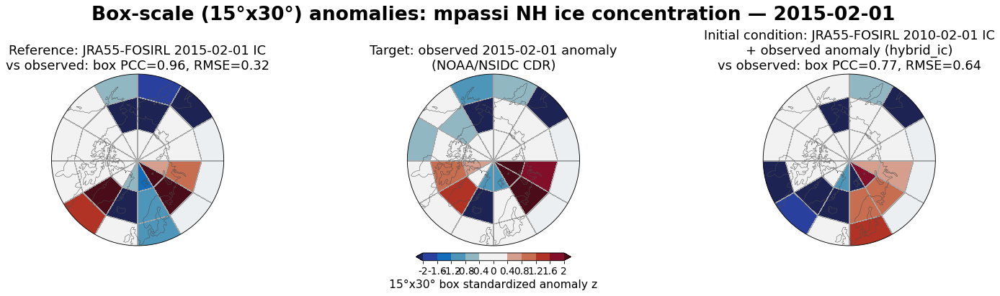

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/box15x30_z_mpassi_sh_ice_concentration_20150201.png


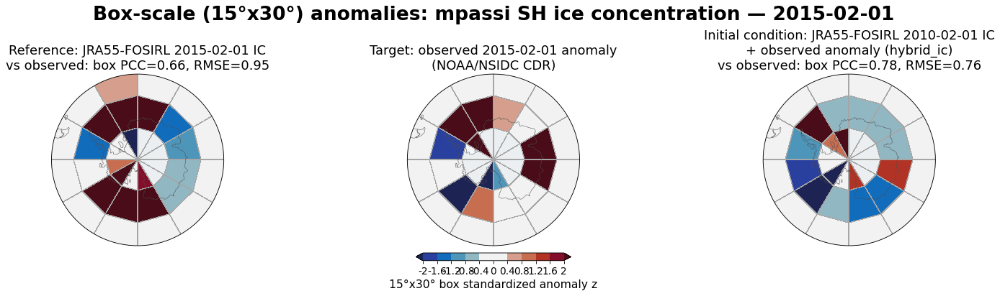

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/box15x30_z_elm_snow_water_equivalent_20150201.png


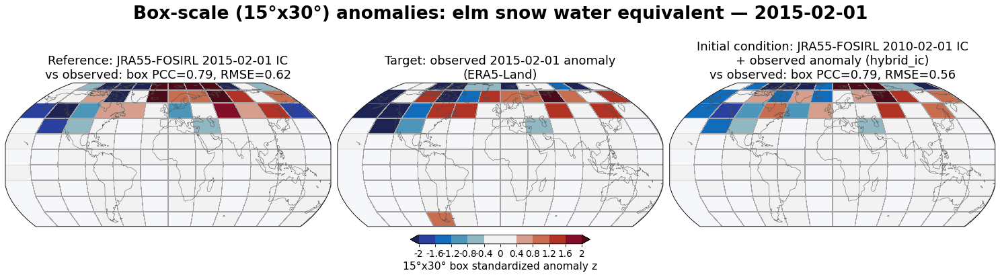

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/box15x30_z_elm_surface_soil_water_20150201.png


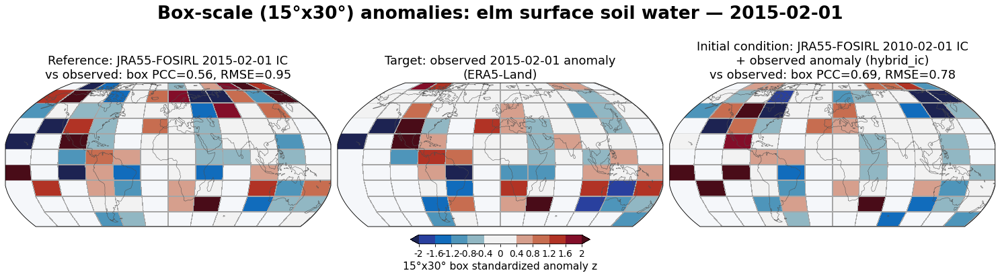

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/box15x30_z_elm_subsurface_soil_water_20150201.png


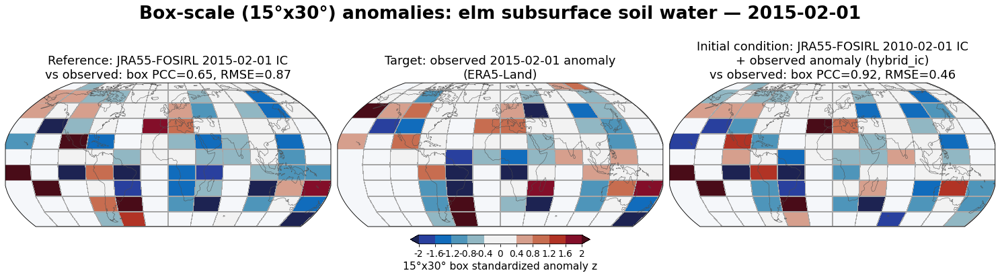

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/box15x30_z_elm_surface_soil_temperature_20150201.png


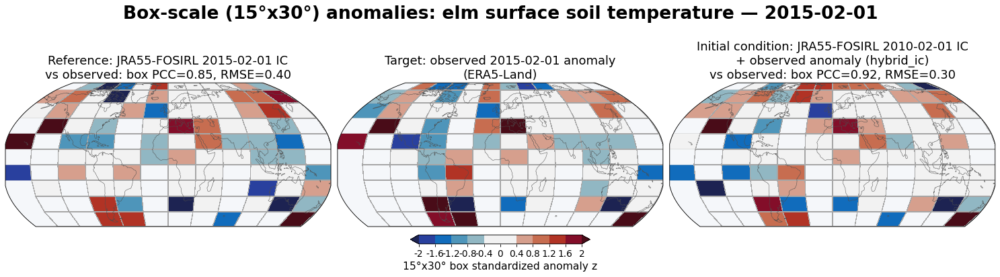

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/box15x30_z_elm_subsurface_soil_temperature_20150201.png


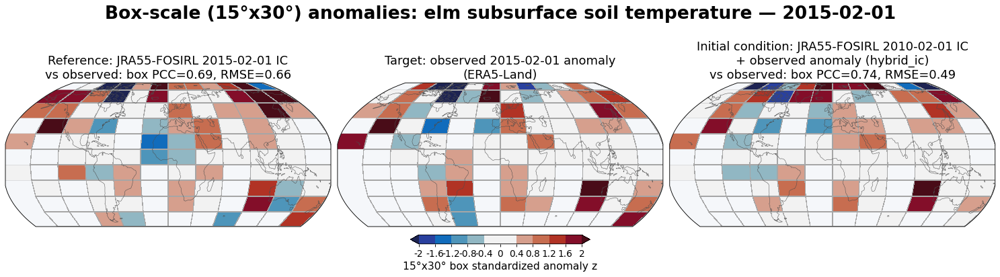

In [17]:
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE = 14
PANEL_SIZE = None
Z_LIM = 2.0          # color range of the box anomaly maps
BOX_FIELDS = [("mpassi", "NH ice concentration"), ("mpassi", "SH ice concentration"),
              ("elm", "snow water equivalent"), ("elm", "surface soil water"), ("elm", "subsurface soil water"),
              ("elm", "surface soil temperature"), ("elm", "subsurface soil temperature")]
# ---------------------------------------------------------------------------------------------
for comp, name in BOX_FIELDS:
    sp = ice.prepare_spatial_field(plans[EXAMPLE_DATE], comp, name, int(EXAMPLE_DATE[:4]),
                                   {METHOD: base_years[EXAMPLE_DATE]["elm"]}, obs_plans={EVAL_OBS["label"]: plans[EXAMPLE_DATE]},
                                   states={METHOD: states[EXAMPLE_DATE]}, box=BOX, cache_dir=CACHE_DIR)
    fig = ice.plot_box_spatial(sp, z_lim=Z_LIM, fontsize=FONTSIZE, panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"box{BOX[0]:g}x{BOX[1]:g}_z_{comp}_{ice.slugify(name)}_{EXAMPLE_DATE.replace('-', '')}",
                 DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 6.5 Soil moisture and soil temperature profiles (`EXAMPLE_DATE`)

Region-mean vertical profiles for one date, to check that the adjusted soil profiles stay continuous and
move toward the observations:

- **Model climatology** (grey): mean over the candidate years.
- **Model before** (blue, dashed): the `clim` year used as the base.
- **Model after** (red): the new `hybrid_ic` initial condition.
- **Observation** (black bars): ERA5-Land at its four soil levels (0-7, 7-28, 28-100, 100-289 cm); each bar
  spans the level's depth range.

Soil moisture is volumetric water content (m3/m3; model liquid + ice divided by layer thickness), soil
temperature is in K. The top row shows absolute values (model and observation climatologies differ); the
bottom rows show anomalies from each source's own climatology, which is what the adjustment uses.
Model layers below 3.8 m hold no water and are not shown.

The adjustment transfers the observed *standardized* anomaly, scaled by the model's own interannual
variability, so the model anomaly after the adjustment should match the observation in sign and vertical shape,
while its magnitude follows the model's variability (soil-moisture variability differs most between ERA5-Land
and E3SM). Region means also mix columns with different anomalies.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/hybrid_ic_soil_profiles_20150201.png


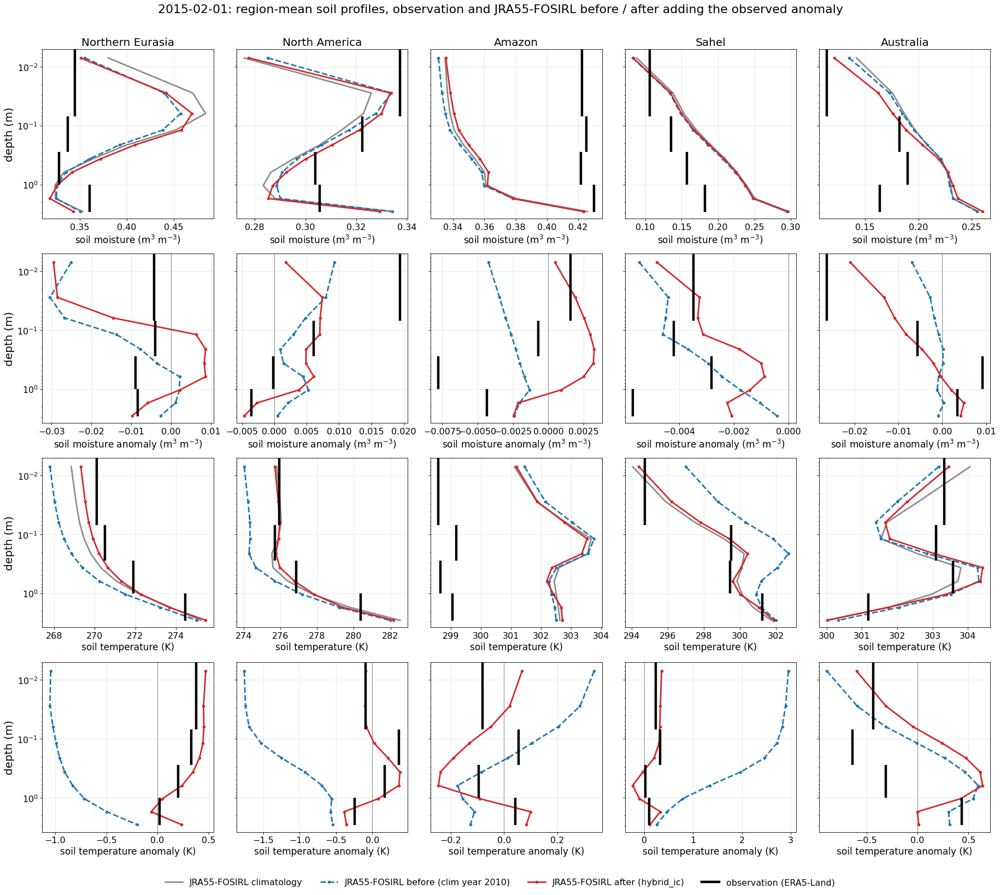

In [18]:
# Region-mean soil moisture and temperature profiles: observation, model before and after the adjustment.
# ---- Figure setup (all adjustable settings) --------------------------------------------
DATE        = EXAMPLE_DATE
REGIONS     = {                  # name: (lat0, lat1, lon0, lon1), lon in degrees east
    "Northern Eurasia": (50, 70, 30, 140),
    "North America": (30, 55, -125, -70),
    "Amazon": (-15, 5, -75, -45),
    "Sahel": (5, 20, -15, 40),
    "Australia": (-35, -15, 115, 150),
}
FONTSIZE    = 18                 # base font size: panel titles and axis labels; other text scales from it
PANEL_SIZE  = (4.6, 5.2)         # width, height of one panel (inches)
MAX_DEPTH   = 3.8                # deepest depth shown (m)
LOG_DEPTH   = True               # log depth axis (resolves the thin top layers)
COLORS      = {"clim": "0.55", "base": "tab:blue", "new": "tab:red", "obs": "k"}
LINE_WIDTH  = 2.5
# -----------------------------------------------------------------------------------------
plan = plans[DATE]
prof = anom_restart.soil_profiles(plan, base_years[DATE]["elm"], plan.output("elm"), REGIONS, log=quiet)
fs = {"title": FONTSIZE, "label": FONTSIZE, "tick": 0.8 * FONTSIZE, "legend": 0.8 * FONTSIZE,
      "suptitle": 1.1 * FONTSIZE}
z, zi = prof["depth"], prof["interfaces"]
levels = list(prof["obs_levels"].values())
rows = [("theta", "abs", "soil moisture (m$^3$ m$^{-3}$)"), ("theta", "anom", "soil moisture anomaly (m$^3$ m$^{-3}$)"),
        ("tsoi", "abs", "soil temperature (K)"), ("tsoi", "anom", "soil temperature anomaly (K)")]
fig, axes = plt.subplots(len(rows), len(prof["regions"]),
                         figsize=(PANEL_SIZE[0] * len(prof["regions"]), PANEL_SIZE[1] * len(rows)),
                         sharey=True, squeeze=False)
for r, (key, kind, label) in enumerate(rows):
    for c, region in enumerate(prof["regions"]):
        ax = axes[r, c]
        mclim, oclim = prof["model"]["clim"][key][c], prof["obs"]["clim"][key][c]
        ref_m, ref_o = (mclim, oclim) if kind == "anom" else (0.0, 0.0)
        if kind == "abs":
            ax.plot(mclim, z, "-", color=COLORS["clim"], lw=LINE_WIDTH, label=f"{IC_SOURCE} climatology")
        else:
            ax.axvline(0, color=COLORS["clim"], lw=1)
        ax.plot(prof["model"]["base"][key][c] - ref_m, z, "--o", color=COLORS["base"], lw=LINE_WIDTH, ms=4,
                label=f"{IC_SOURCE} before (clim year {base_years[DATE]['elm']})")
        ax.plot(prof["model"]["new"][key][c] - ref_m, z, "-o", color=COLORS["new"], lw=LINE_WIDTH, ms=4,
                label=f"{IC_SOURCE} after (hybrid_ic)")
        obs = prof["obs"]["target"][key][c] - ref_o
        for (top, bot), v in zip(levels, obs):
            ax.plot([v, v], [max(top, 0.005), bot], color=COLORS["obs"], lw=LINE_WIDTH + 1.5,
                    solid_capstyle="butt")
        ax.plot([], [], color=COLORS["obs"], lw=LINE_WIDTH + 1.5, label=f"observation ({OBS_NAME.split('/')[0]})")
        if LOG_DEPTH:
            ax.set_yscale("log")
        ax.set_ylim(MAX_DEPTH, 0.005 if LOG_DEPTH else 0)
        ax.tick_params(labelsize=fs["tick"])
        ax.grid(alpha=0.3)
        if r == 0:
            ax.set_title(region, fontsize=fs["title"])
        if c == 0:
            ax.set_ylabel("depth (m)", fontsize=fs["label"])
        ax.set_xlabel(label, fontsize=0.85 * fs["label"])
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=fs["legend"], loc="lower center", ncol=len(labels), frameon=False)
fig.suptitle(f"{DATE}: region-mean soil profiles, observation and {IC_SOURCE} before / after adding the observed anomaly",
             fontsize=fs["suptitle"])
fig.tight_layout(rect=(0, 0.035, 1, 0.97))
ice.save_fig(fig, f"hybrid_ic_soil_profiles_{DATE.replace('-', '')}", DIAG, SAVE_DIAG, dpi=FIG_DPI)
plt.show()

## 7. Native-mesh maps

Plotted directly on the model meshes with [`mosaic`](https://docs.e3sm.org/mosaic/): the unstructured
MPAS-Seaice mesh (`IcoswISC30E3r5`) in polar stereographic projections and the ELM `grid1d` land cells.

### 7.1 MPAS-Seaice: state and error (`EXAMPLE_DATE`)

NH (top) and SH (bottom): the JRA55-FOSIRL 2015 IC (reference), the initial condition (PCC and RMSE against
the reference), and the error (initial condition minus reference).

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/mpassi_state_diff_ice_concentration_20150201.png


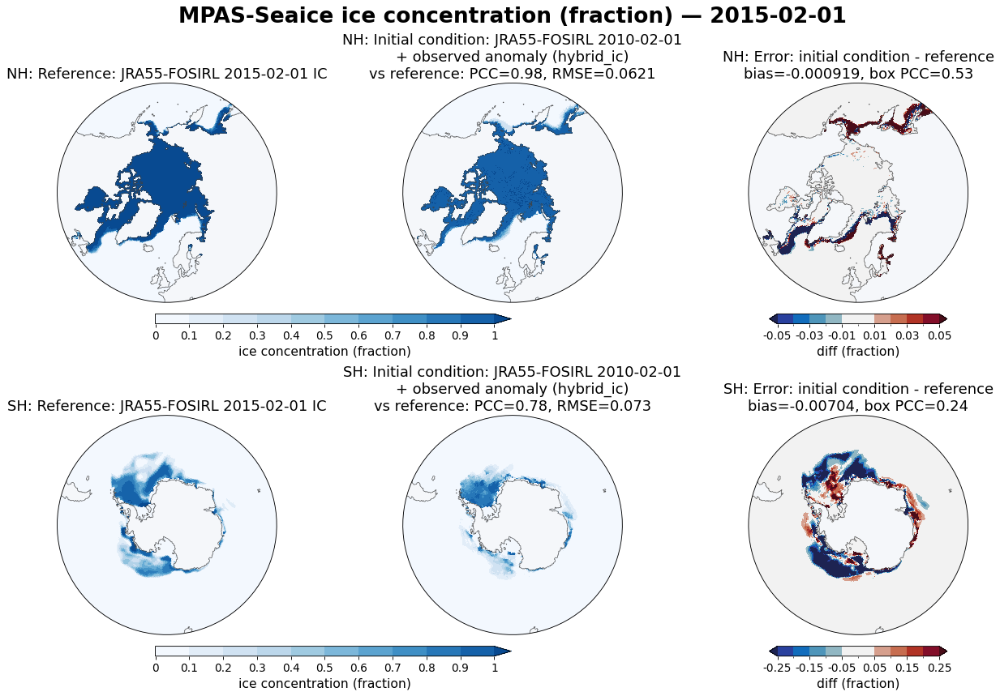

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/mpassi_state_diff_ice_thickness_20150201.png


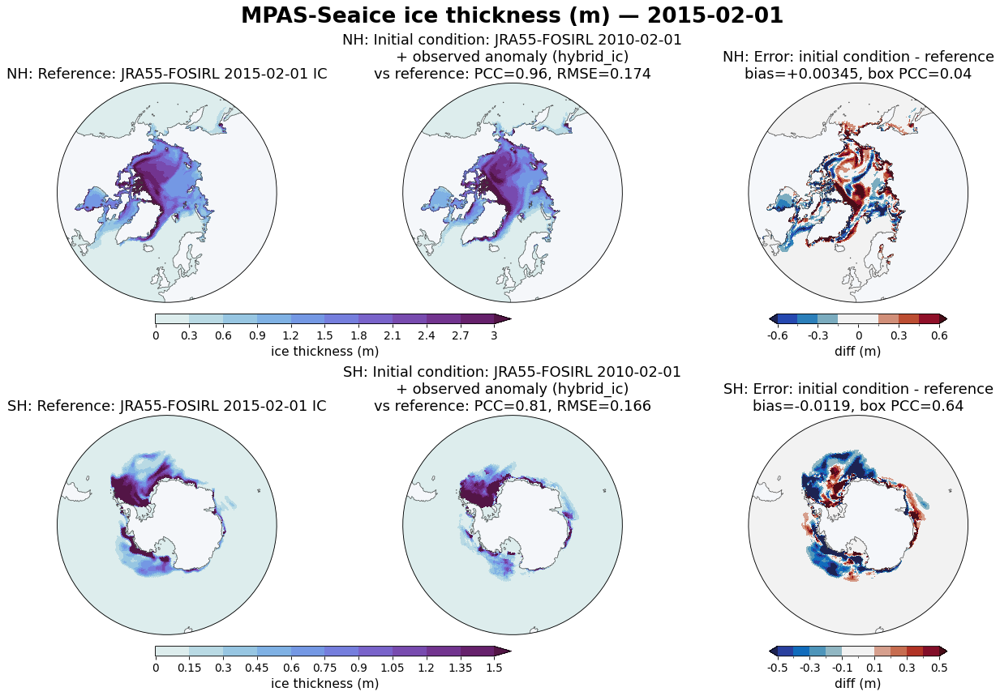

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/mpassi_state_diff_snow_on_ice_20150201.png


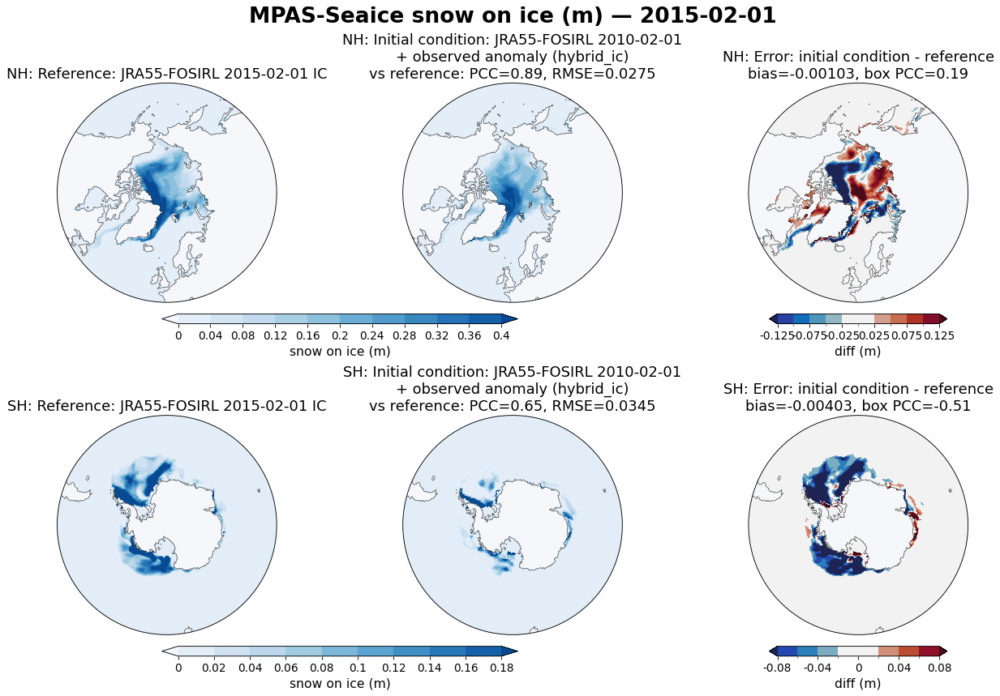

In [19]:
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE = 14
PANEL_SIZE = None
QUANTITIES = ["ice concentration", "ice thickness", "snow on ice"]   # each plotted for NH and SH
# ---------------------------------------------------------------------------------------------
mesh_file = cr.source_file(SRC_ROOT, SRC_PREFIX, "mpassi", int(EXAMPLE_DATE[:4]), EXAMPLE_DATE[5:])
mpassi_desc = ice.build_mpassi_descriptors(mesh_file)
spatial_mpassi = {}
for quantity in QUANTITIES:
    for hemi in ("NH", "SH"):
        name = f"{hemi} {quantity}"
        spatial_mpassi[name] = ice.prepare_spatial_field(
            plans[EXAMPLE_DATE], "mpassi", name, int(EXAMPLE_DATE[:4]), {METHOD: base_years[EXAMPLE_DATE]["mpassi"]},
            obs_plans={EVAL_OBS["label"]: plans[EXAMPLE_DATE]}, states={METHOD: states[EXAMPLE_DATE]},
            box=BOX, cache_dir=CACHE_DIR)
    fig = ice.plot_mpassi_spatial([spatial_mpassi[f"NH {quantity}"], spatial_mpassi[f"SH {quantity}"]], mpassi_desc,
                                  kind="state_and_diff", fontsize=FONTSIZE, panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"mpassi_state_diff_{ice.slugify(quantity)}_{EXAMPLE_DATE.replace('-', '')}",
                 DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 7.2 MPAS-Seaice: standardized anomalies (`EXAMPLE_DATE`)

The JRA55-FOSIRL 2015 IC (the reference), the observed anomaly (the target), and the initial condition, as
standardized anomalies z; PCC, RMSE, and box PCC compare the reference and the initial condition with the
observed anomaly. Fields without an observation (ice thickness) compare the initial condition with the
JRA55-FOSIRL 2015 IC.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/mpassi_z_ice_concentration_20150201.png


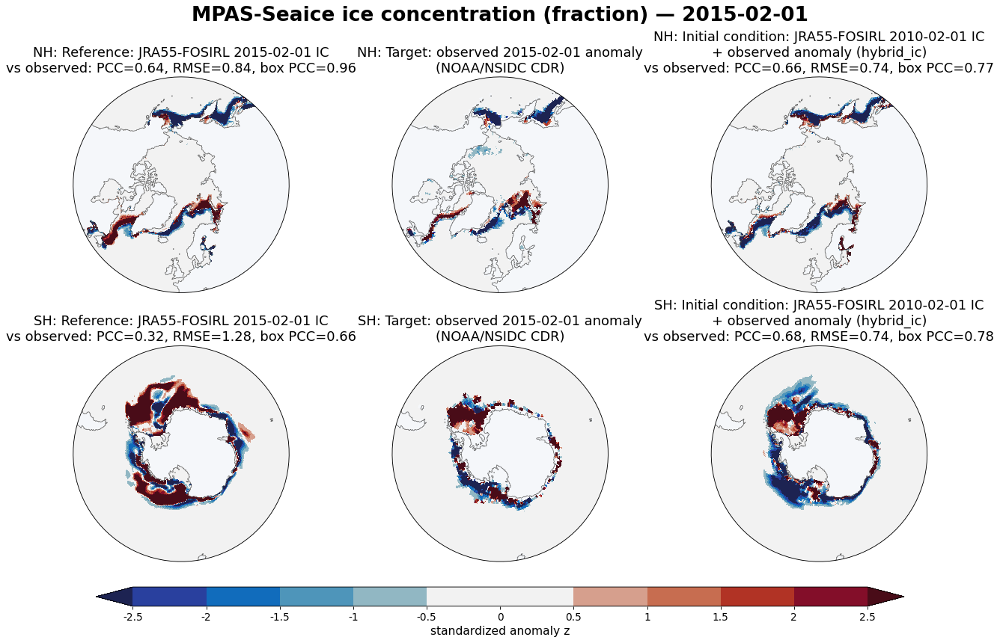

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/mpassi_z_ice_thickness_20150201.png


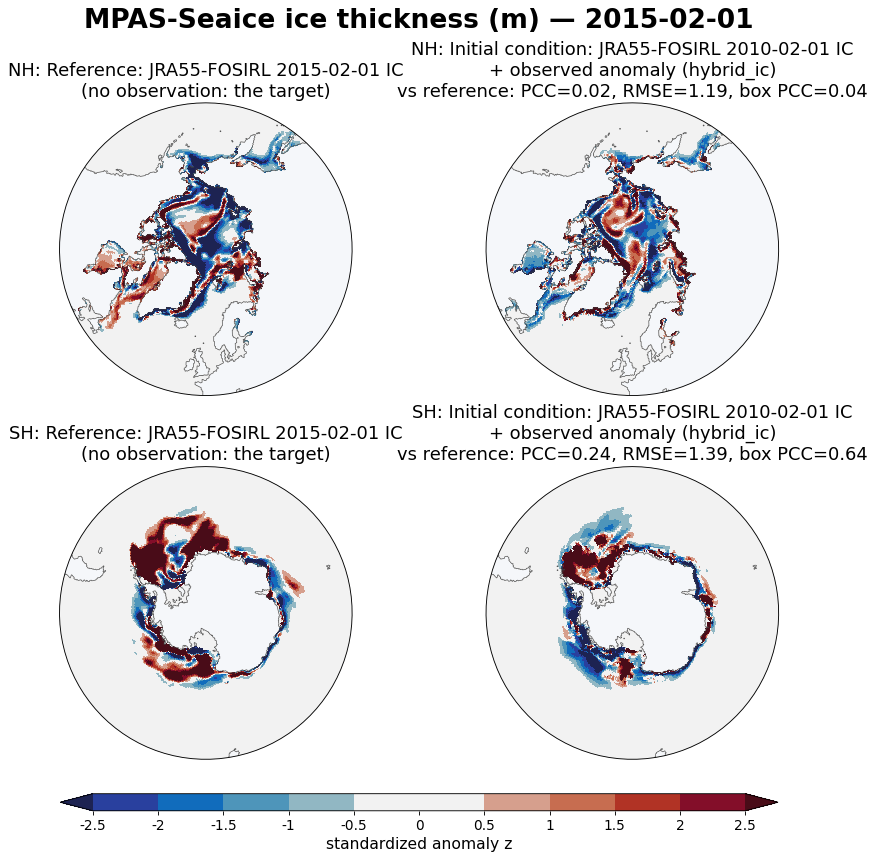

In [20]:
Z_LIM = 2.5          # color range of the standardized anomaly maps
for quantity in ["ice concentration", "ice thickness"]:
    fig = ice.plot_mpassi_spatial([spatial_mpassi[f"NH {quantity}"], spatial_mpassi[f"SH {quantity}"]], mpassi_desc,
                                  kind="z", z_lim=Z_LIM, fontsize=FONTSIZE, panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"mpassi_z_{ice.slugify(quantity)}_{EXAMPLE_DATE.replace('-', '')}", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 7.3 MPAS-Seaice: four 2015 dates

JRA55-FOSIRL 2015 sea-ice concentration and the error of the initial condition on each 2015 date.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/mpassi_4seasons_nh_ice_concentration_2015.png


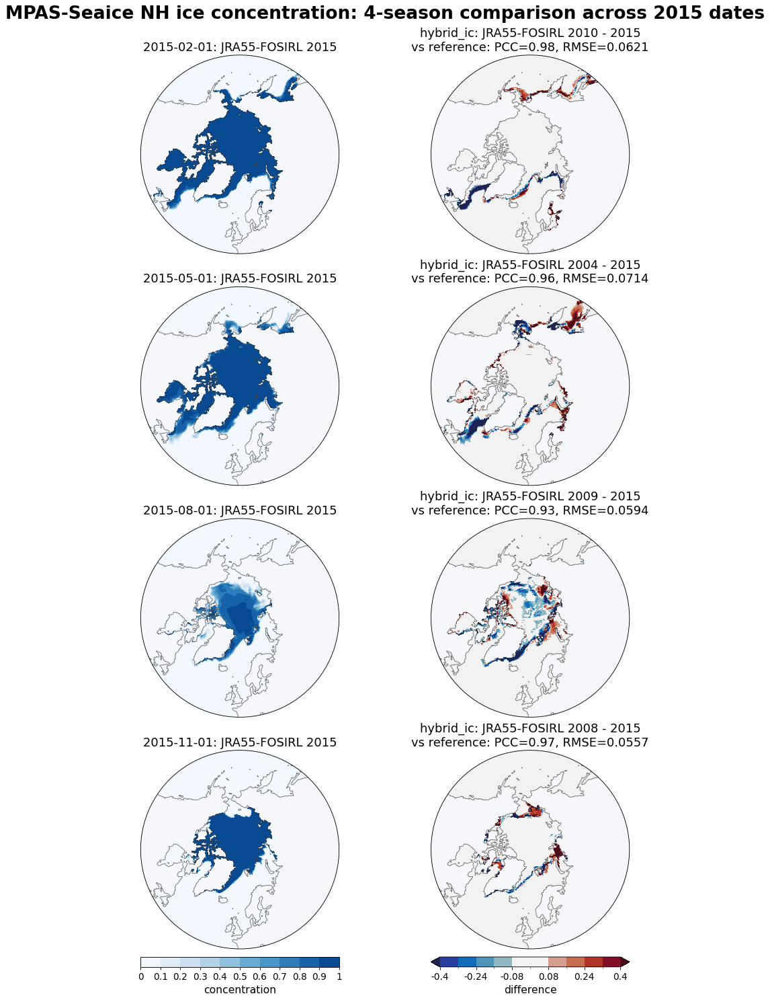

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/mpassi_4seasons_sh_ice_concentration_2015.png


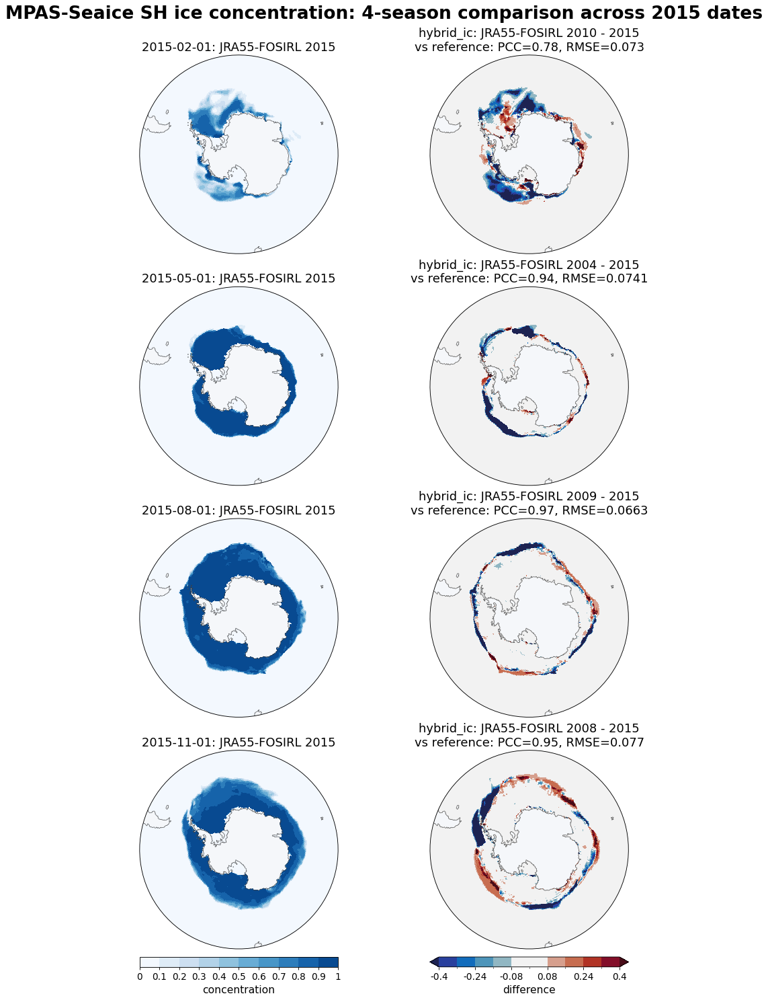

In [21]:
DIFF_LIM = 0.4       # color range of the concentration differences
for name in ["NH ice concentration", "SH ice concentration"]:
    fig = ice.plot_mpassi_four_seasons(name, EVAL_DATES, eval_plans, {(METHOD, d): base_years[d] for d in EVAL_DATES},
                                       mpassi_desc, states={d: {METHOD: states[d]} for d in EVAL_DATES},
                                       box=BOX, cache_dir=CACHE_DIR, diff_lim=DIFF_LIM, fontsize=FONTSIZE,
                                       panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"mpassi_4seasons_{ice.slugify(name)}_2015", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 7.4 ELM: state and error (`MAP_DATES`)

Rows: snow water equivalent, surface and subsurface soil water, surface and subsurface soil temperature.
Columns: the JRA55-FOSIRL 2015 IC (reference), the candidate-year climatology (baseline, no selection), the
initial condition (PCC and RMSE against the reference), and the error in percent of the reference (bias and
box PCC in the title).

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_state_diff_20150201.png


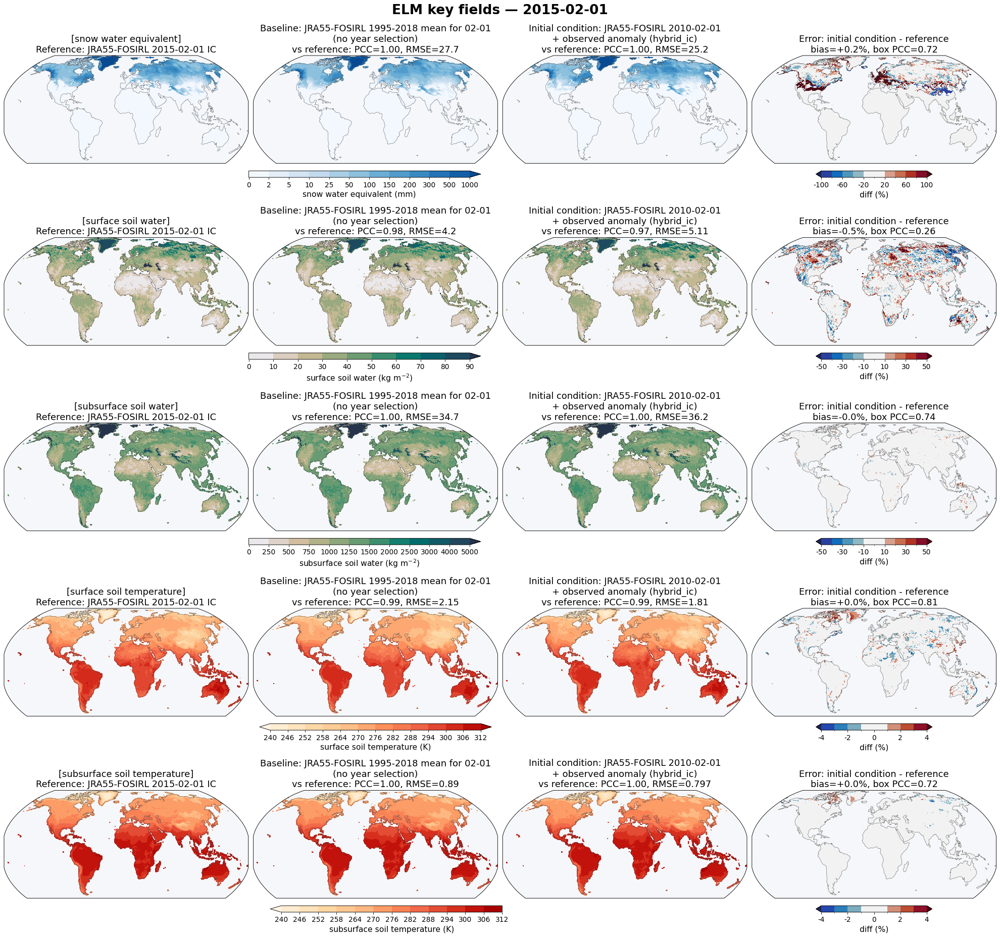

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_state_diff_20150501.png


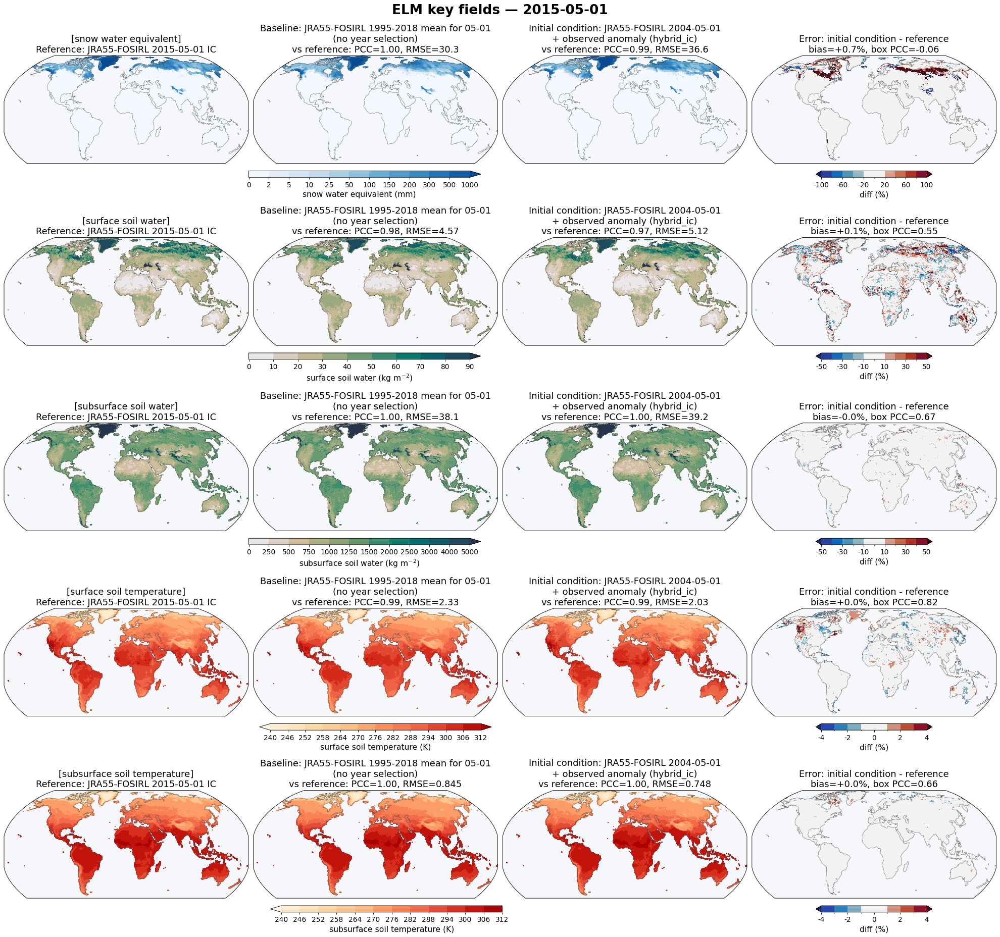

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_state_diff_20150801.png


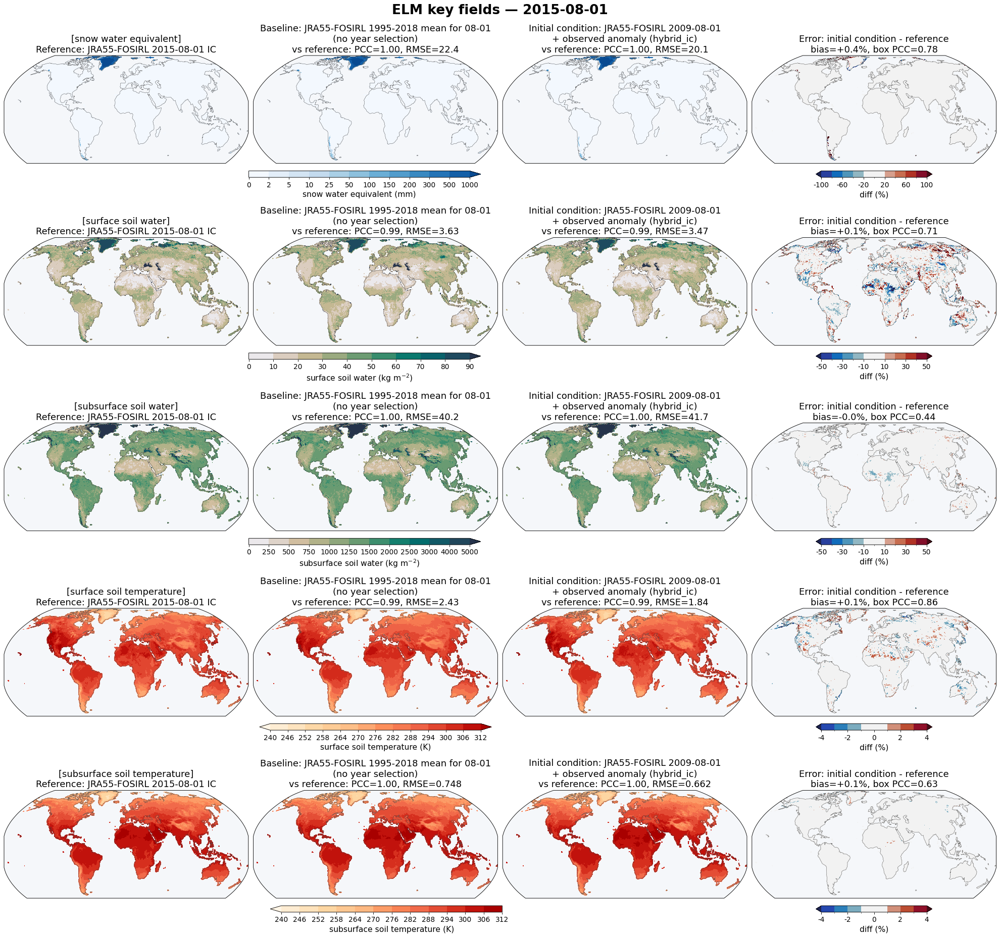

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_state_diff_20151101.png


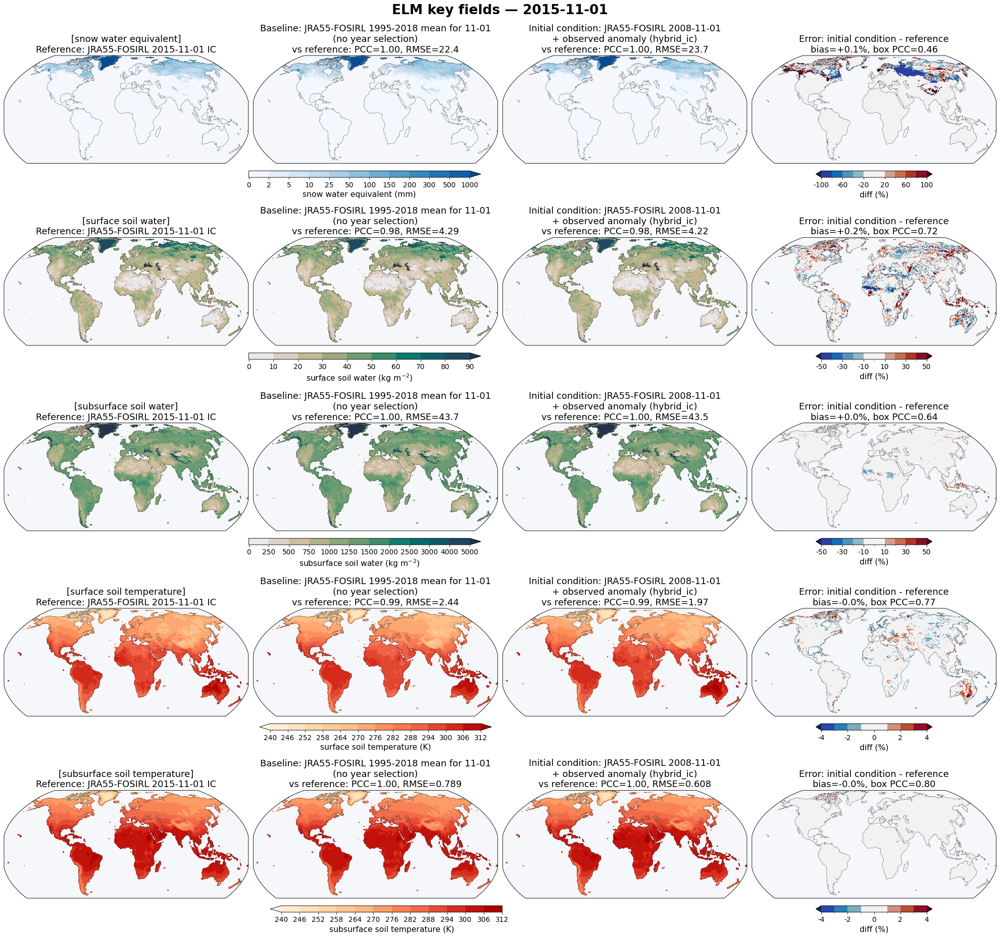

In [22]:
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE = 14
PANEL_SIZE = None
ELM_FIELDS = ["snow water equivalent", "surface soil water", "subsurface soil water",
              "surface soil temperature", "subsurface soil temperature"]
# ---------------------------------------------------------------------------------------------
points = cr.comparison_points(plans[EXAMPLE_DATE], "elm", CACHE_DIR)
elm_desc = ice.build_elm_descriptor(points["lat"], points["lon"])
spatial_elm = {}
for date in MAP_DATES:
    spatial_elm[date] = {
        name: ice.prepare_spatial_field(plans[date], "elm", name, int(date[:4]), {METHOD: base_years[date]["elm"]},
                                        obs_plans={EVAL_OBS["label"]: plans[date]}, states={METHOD: states[date]},
                                        box=BOX, cache_dir=CACHE_DIR)
        for name in ELM_FIELDS
    }
    fig = ice.plot_elm_spatial([spatial_elm[date][f] for f in ELM_FIELDS], elm_descriptor=elm_desc,
                               kind="state_and_diff", fontsize=FONTSIZE, panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"elm_state_diff_{date.replace('-', '')}", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 7.5 ELM: standardized anomalies (`MAP_DATES`)

The JRA55-FOSIRL 2015 IC (the reference), the observed anomaly (the target), and the initial condition; PCC,
RMSE (in standard deviations), and box PCC compare the reference and the initial condition with the observed
anomaly.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_z_20150201.png


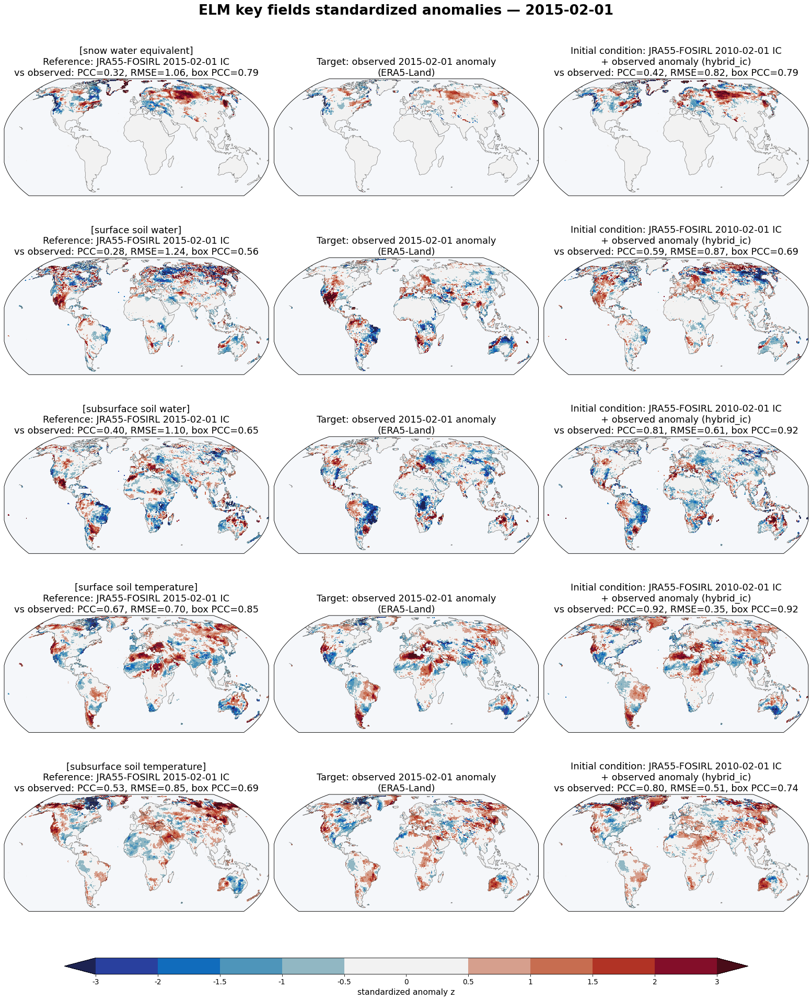

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_z_20150501.png


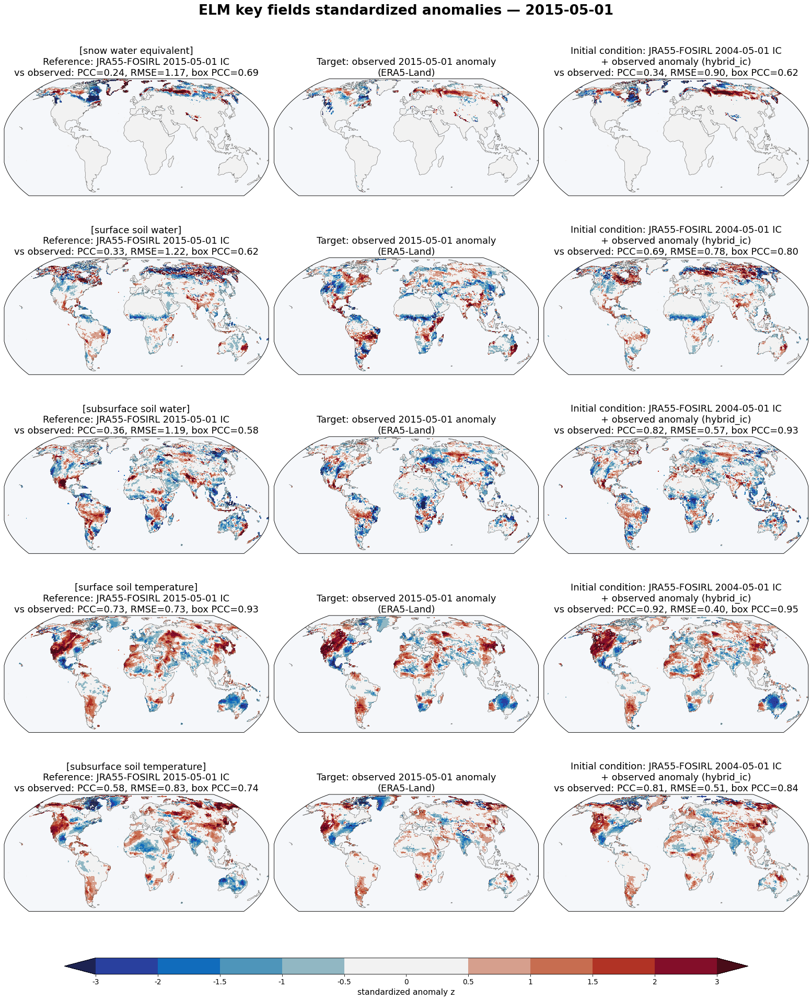

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_z_20150801.png


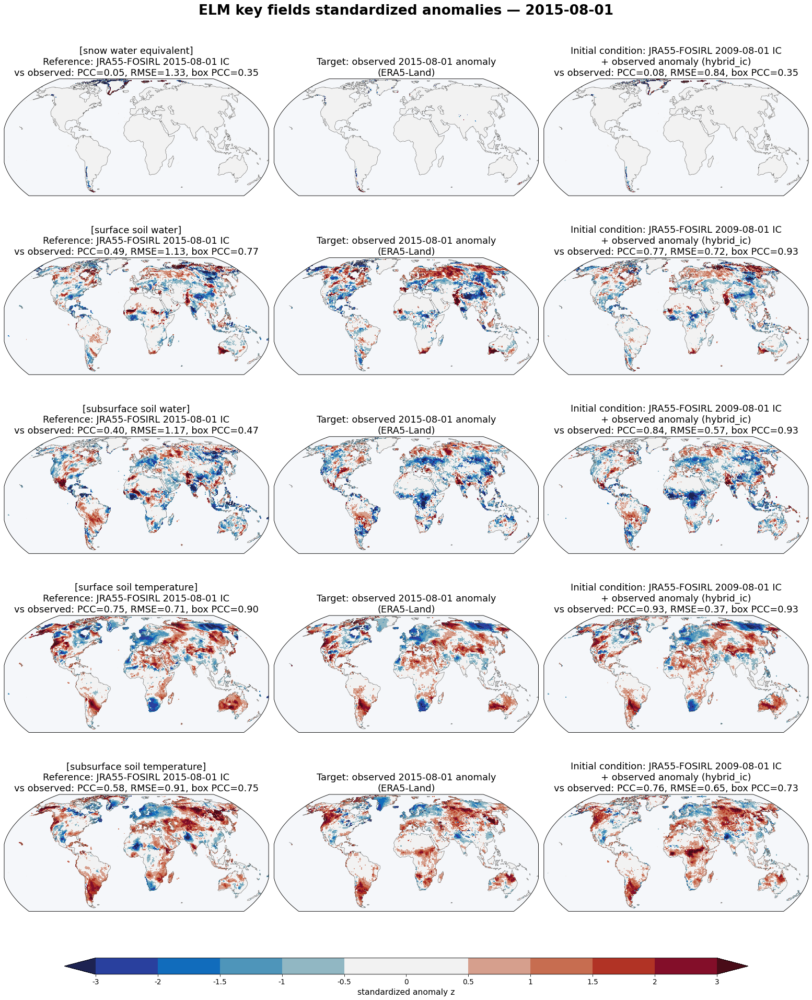

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_z_20151101.png


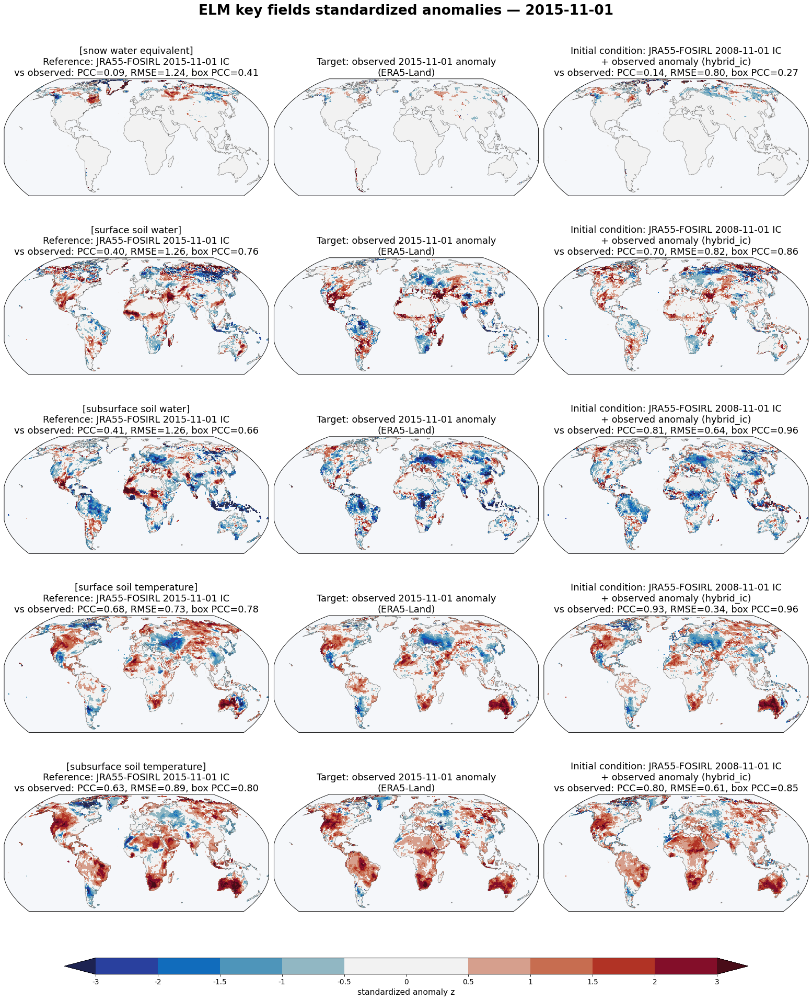

In [23]:
Z_LEVELS = [-3, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 3]
for date in MAP_DATES:
    fig = ice.plot_elm_spatial([spatial_elm[date][f] for f in ELM_FIELDS], elm_descriptor=elm_desc, kind="z",
                               z_lim=Z_LEVELS[-1], z_levels=Z_LEVELS, fontsize=FONTSIZE, panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"elm_z_{date.replace('-', '')}", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 7.6 ELM: four 2015 dates

Standardized anomalies of each land field on the four 2015 dates: the JRA55-FOSIRL 2015 IC (the reference),
the observed anomaly (the target), and the initial condition.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_4seasons_z_snow_water_equivalent_2015.png


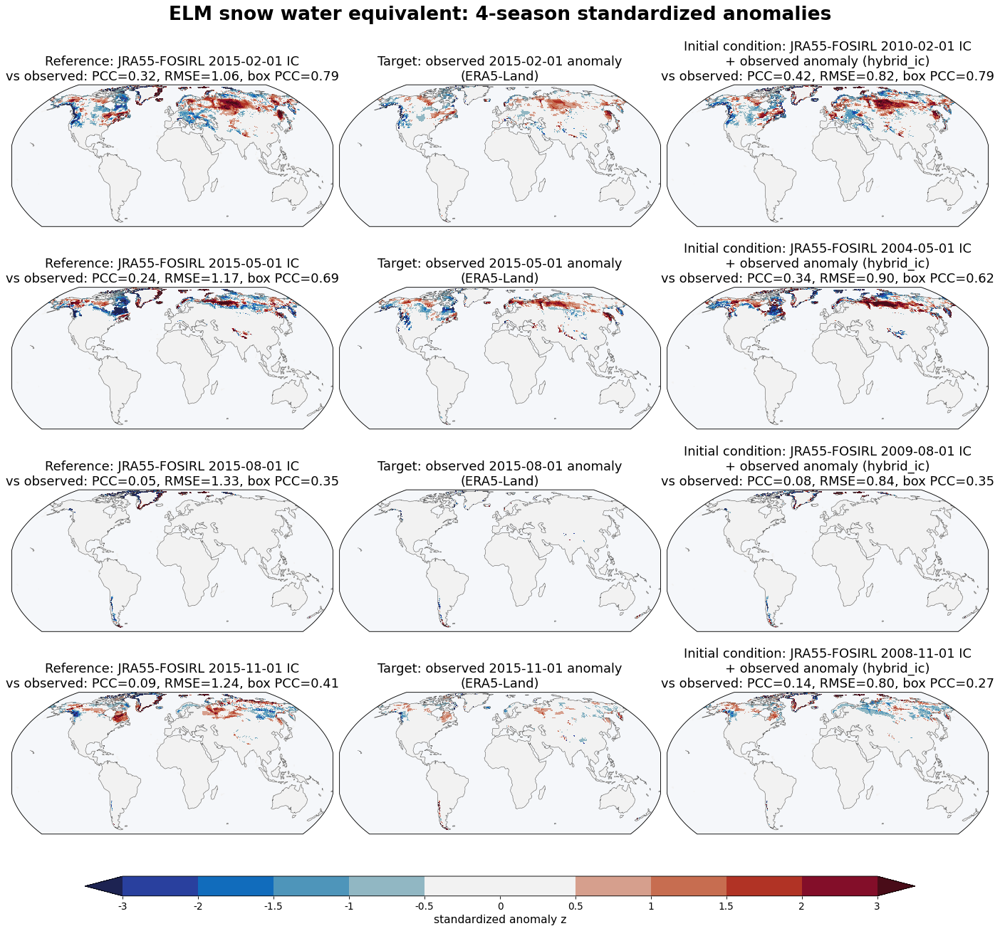

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_4seasons_z_surface_soil_water_2015.png


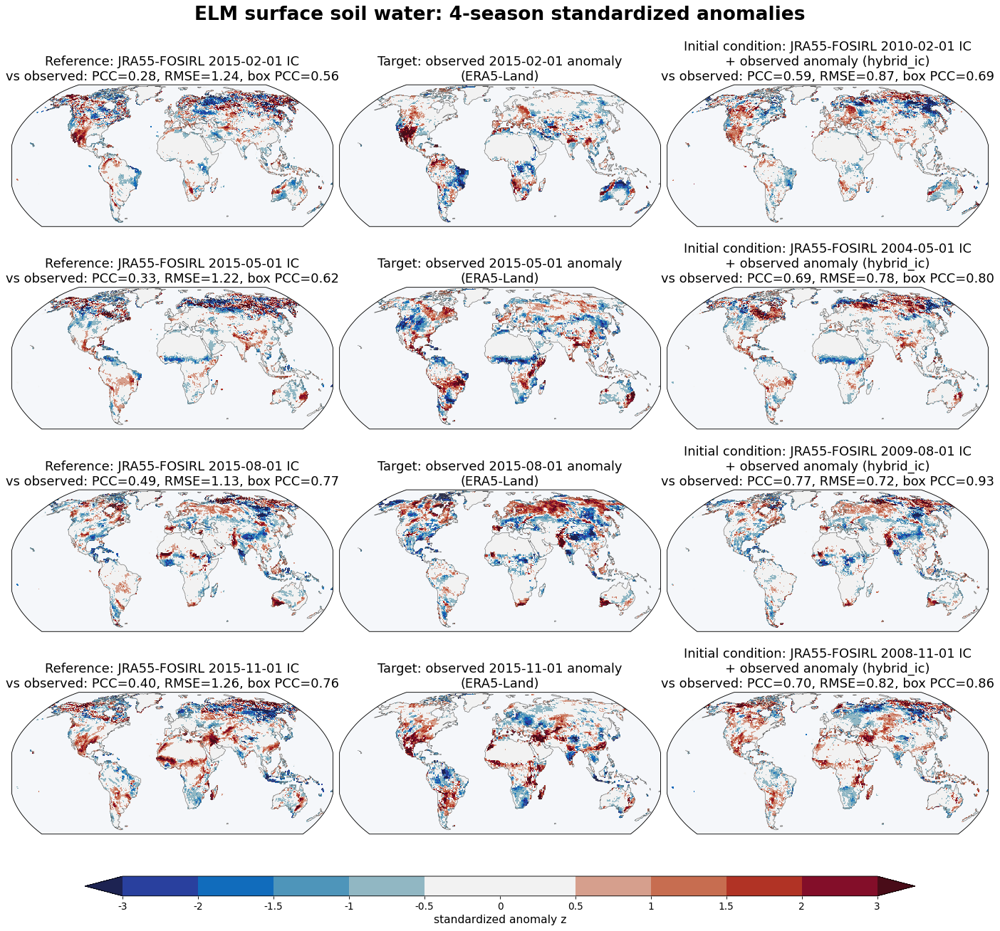

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_4seasons_z_subsurface_soil_water_2015.png


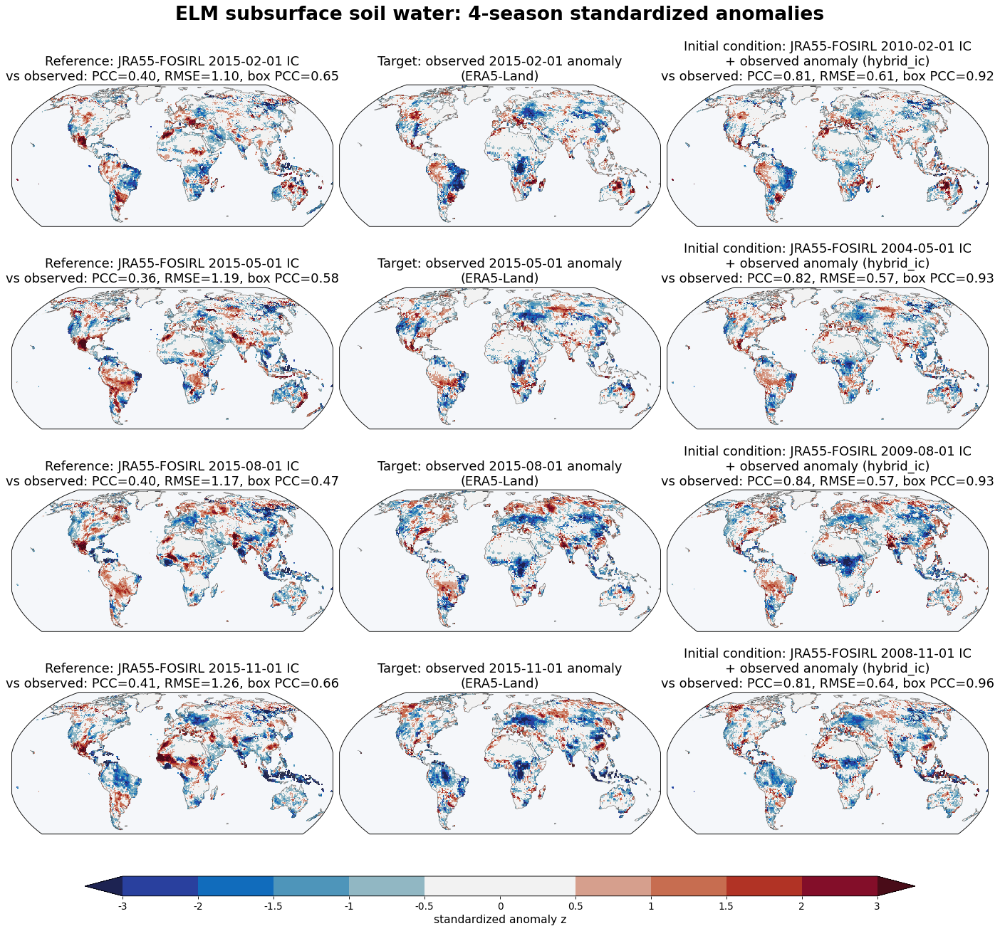

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_4seasons_z_surface_soil_temperature_2015.png


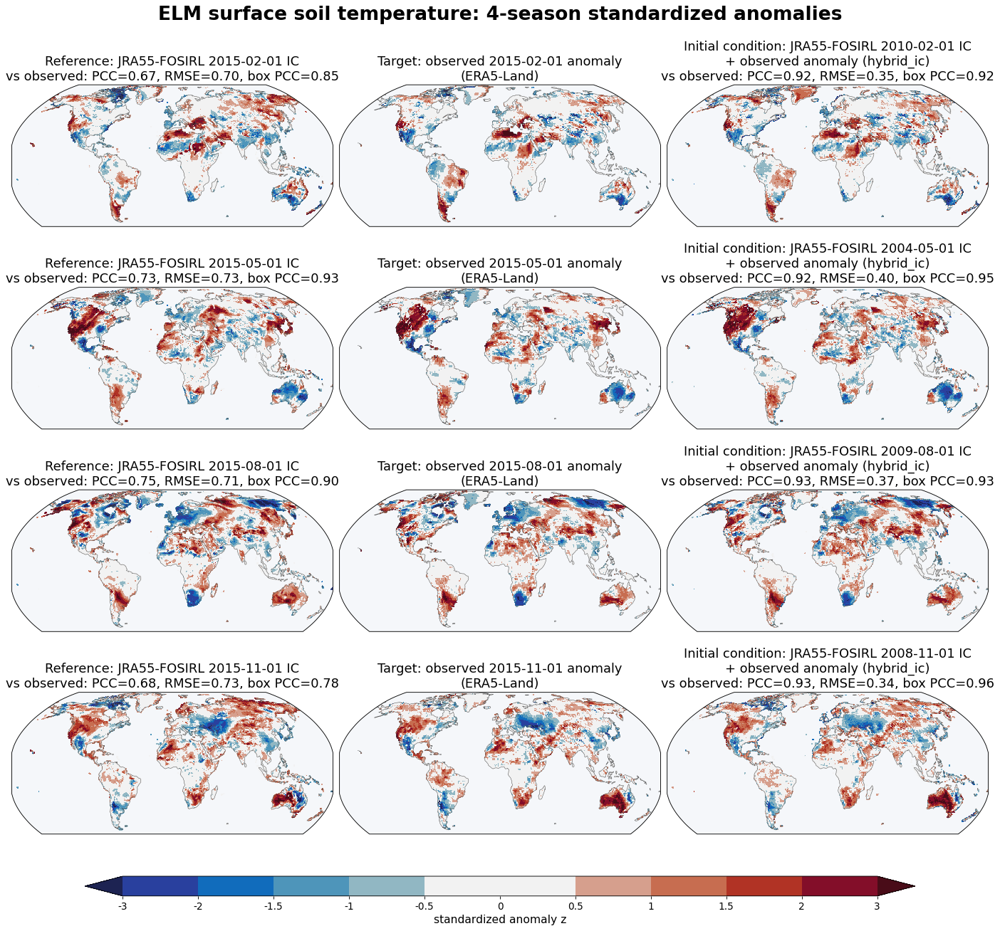

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/figure/elm_4seasons_z_subsurface_soil_temperature_2015.png


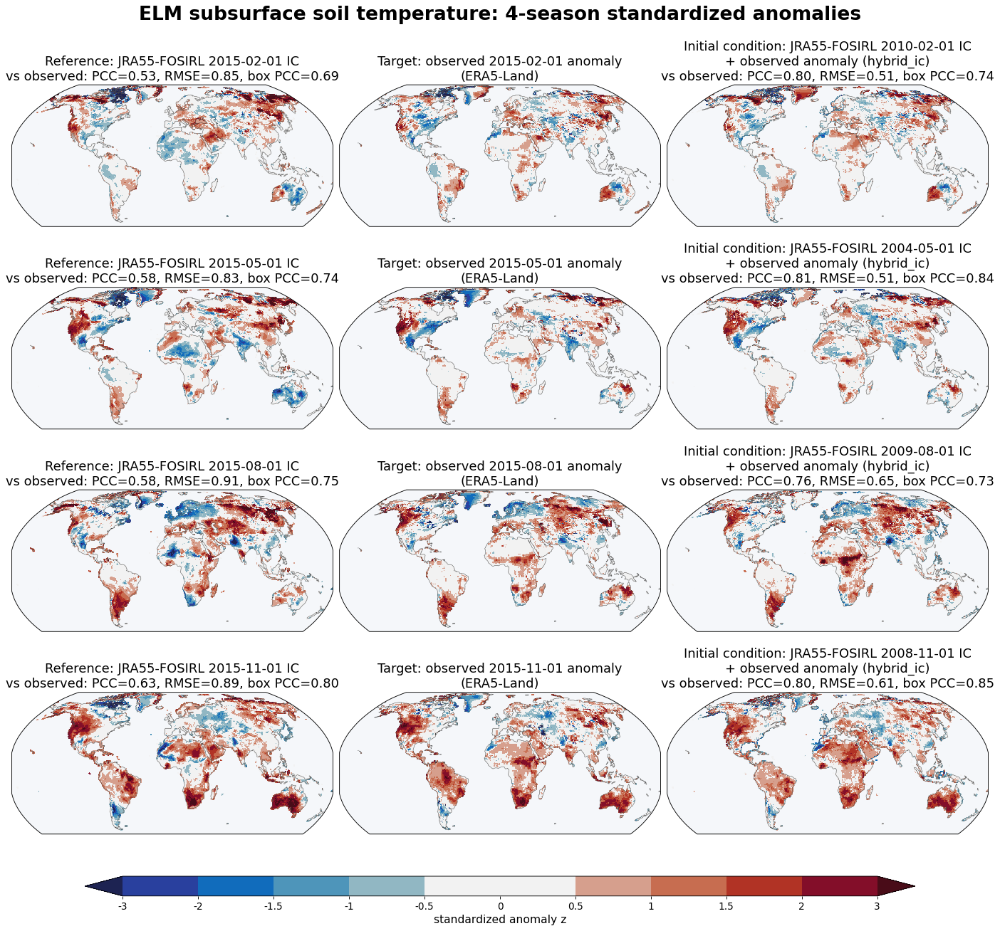

In [24]:
Z_LIM = 2.5
for name in ELM_FIELDS:
    fig = ice.plot_elm_four_seasons(name, EVAL_DATES, eval_plans, {(METHOD, d): base_years[d] for d in EVAL_DATES},
                                    elm_desc, obs_refs={METHOD: EVAL_OBS["label"]},
                                    states={d: {METHOD: states[d]} for d in EVAL_DATES},
                                    box=BOX, cache_dir=CACHE_DIR, z_lim=Z_LIM, fontsize=FONTSIZE,
                                    panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"elm_4seasons_z_{ice.slugify(name)}_2015", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

## 8. Save the outputs for comparing the methods

Written to `DIAG_ROOT/<METHOD>/data/` in the same layout by 01, 02, and 03 (`util/ic_store.py`), and read by
`04_compare_ic_methods.ipynb`:

- `config.json`: the settings of this run;
- `selection.csv`: the year used for each date and component;
- `states_YYYYMMDD.npz`: the initial-condition key fields at model points, for every target date;
- `input_summary.csv`, `distances.csv`, `state_distance.csv`, `field_similarity.csv`, `global_summary.csv`
  and `increment_stats.csv` (the base year is in `selection.csv`).

In [25]:
if SAVE_DIAG:
    config = {name: value for name, value in globals().items()
              if name.isupper() and isinstance(value, (str, int, float, bool, list, tuple, dict, Path, type(None)))}
    config["SETTINGS"] = anom_restart.asdict(SETTINGS)
    print(ic_store.save_config(DIAG_ROOT, METHOD, config))
    rows = [{"target_date": d, "component": c, "year": y, "role": "base",
             "candidate years": f"{plans[d].candidate_years[0]}-{plans[d].candidate_years[-1]}",
             "climatology years": f"{plans[d].clim_years[0]}-{plans[d].clim_years[-1]}"}
            for d in plans for c, y in base_years[d].items()]
    ice.save_table(pd.DataFrame(rows), "selection", DIAG, SAVE_DIAG)
    ice.save_table(inputs, "input_summary", DIAG, SAVE_DIAG)
    ice.save_table(pd.concat([t.reset_index().assign(target_date=d) for d, t in distances.items()]),
                   "distances", DIAG, SAVE_DIAG)
    ice.save_table(state_eval, "state_distance", DIAG, SAVE_DIAG)
    for date in states:
        print(ic_store.save_states(DIAG_ROOT, METHOD, date, states[date], base_years[date]))
    ice.save_table(stats.reset_index(), "increment_stats", DIAG, SAVE_DIAG)

/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/config.json
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/selection.csv
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/input_summary.csv
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/distances.csv
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/state_distance.csv


/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/states_20150201.npz


/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/states_20150501.npz


/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/states_20150801.npz


/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/states_20151101.npz


/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/states_20260201.npz


/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/states_20260501.npz


/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/states_20260801.npz
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/hybrid_ic/data/increment_stats.csv


## 9. Key findings

Default settings: base year from the climatology match (as in `01_clim_match_ic.ipynb`), anomaly from
ERA5-Land (land) and NOAA/NSIDC CDR (sea-ice concentration), `scale="point"`, `z_max=3`, envelope on,
continuous soil profiles; candidate and climatology years 1995-2018 (target year excluded). All model states
are JRA55-FOSIRL restarts or built from them.

**Table. Joint distance D of the three initial conditions** (15°x30° boxes, observable fields; lower is
closer). Each cell: JRA55-FOSIRL clim year / JRA55-FOSIRL obs year / **hybrid_ic**. A typical candidate year
has D of about 1.4-1.6 from the observed anomaly.

| Date | vs observed anomaly | vs JRA55-FOSIRL 2015 IC |
|---|---|---|
| 2015-02-01 | 1.24 / 1.11 / **0.63** | 1.38 / 1.16 / **0.96** |
| 2015-05-01 | 1.31 / 1.09 / **0.70** | 1.47 / 0.96 / **1.01** |
| 2015-08-01 | 1.22 / 1.18 / **0.55** | 1.17 / 1.14 / **0.80** |
| 2015-11-01 | 1.46 / 1.16 / **0.71** | 1.55 / 1.21 / **0.98** |
| 2026-02-01 | 1.29 / 1.29 / **0.70** | -- |
| 2026-05-01 | 1.46 / 1.25 / **0.61** | -- |
| 2026-08-01 | 1.50 / 1.33 / **0.59** | -- |

1. **`hybrid_ic` is the closest state to the observed anomaly on every date** (D = 0.55-0.71 on boxes,
   0.70-0.84 at model points, against 1.09-1.50 for the archive years). This is expected: it is built from it.
2. **It is also the closest state to the JRA55-FOSIRL 2015 IC on three of the four 2015 dates** (D =
   0.80-0.98 against 1.14-1.21 for the obs year); in May the obs year is slightly closer (0.96 against 1.01).
   This is an independent check, since 2015 was not used to build it.
3. **The gain comes from soil temperature, soil water, and NH sea ice** (mean field distance from the
   JRA55-FOSIRL 2015 IC on boxes, hybrid_ic against the obs year): surface soil temperature 0.53 vs 1.19,
   subsurface soil temperature 0.70 vs 1.07, surface soil water 0.92 vs 1.33, subsurface soil water 0.91 vs
   1.20, NH ice concentration 0.84 vs 1.06. For snow (1.00 vs 0.78) and SH ice concentration (1.13 vs 1.10)
   the obs year is as close or closer.
4. **Sea ice cannot be created where the base year has none,** so the SH deficit of the base year remains in
   Feb (area -31%, snow volume -68% against the JRA55-FOSIRL 2015 IC).
5. **The written restarts carry exactly the computed key fields** (maximum relative error 5e-8 for ELM and
   MPAS-Seaice). Their stability in the model has not been tested; a short run is needed before use (soil phase
   partition, water table, and sea-ice thickness distribution are not adjusted).

These numbers come from the tables above; update this section if the configuration changes.